# Adım 2 · Veri Anlayışı — Chicago Traffic Tracker, Temmuz 2024

**BSM 429 Veri Madenciliği · Dönem Projesi · Proje l — Otopark ve trafik yoğunluğu · Varyant l3 — Olay tespiti**

Bu defter projenin **2. adımını** (H2 — veri anlayışı) yürütür: veri indirme, tüm sütunların tek tek incelenmesi,
veri sözlüğü, özet istatistikler, beş sayı özeti, EDA grafikleri, aykırı değer taraması ve veri kalitesinin altı boyutu.

| Bu defter ne yapar | Bu defter ne yapmaz |
|---|---|
| Veriyi olduğu gibi okur, ölçer, belgeler | Hiçbir satırı silmez, hiçbir değeri doldurmaz |
| Eksik ve aykırı değerleri **bulgu** olarak raporlar | Eksik/aykırı **kararlarını** vermez — onlar 3. adımın işi (H3) |
| Takvim olayları için bir **ön liste** çıkarır | Anomali tespiti yapmaz — o 8. adımın işi (H11) |

**Dayanak:** H02 (veri sözlüğünün dört sorusu · dört ölçek türü · veri kalitesinin altı boyutu · beş sayı özeti ve 1,5·ÇAA ·
hangi grafik hangi soruyu yanıtlar) ve H03 (eksik değerin kılıkları · eksiklik mekanizması · aykırı değer karar soruları).

> ⚠️ **Ham veri dokunulmadan kalır.** EDA için kurulan her türetilmiş görünüm (ör. `hiz_gecerli`) yalnızca bu defterin içinde yaşar ve
> diske "temizlenmiş veri" olarak yazılmaz. Ön işleme kararları ve sızıntı önlemi 3. adımın konusudur.

## 0 · Kurulum

In [1]:
import gzip
import hashlib
import json
import urllib.parse
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Klasörler — defter hem repo içinden (notebooks/) hem Colab'da (/content) çalışır
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "raw" / "kf7e-cur8_2024-07.csv.gz"
FIG = ROOT / "figures"
OUT = ROOT / "outputs"
for p in (DATA.parent, FIG, OUT):
    p.mkdir(parents=True, exist_ok=True)

# Grafik biçimi — tek bir görsel sistem: ince işaretler, silik ızgara, sabit renk sırası
C = {"mavi": "#257de0", "turuncu": "#f47230", "turkuaz": "#00b894", "sari": "#f2a600",
     "pembe": "#ee7fac", "yesil": "#008a17", "mor": "#6a4ce2", "kirmizi": "#ec4647",
     "murekkep": "#191919", "ikincil": "#666666", "izgara": "#e7e7e7", "eksen": "#c2c2c2", "notr": "#efefef"}
MAVI_RAMPA = LinearSegmentedColormap.from_list(
    "mavi_rampa", ["#f4f9ff", "#cce3fd", "#9dc8f7", "#6aabf1", "#338ced", "#2370cd", "#1757ac", "#0e3d7e"])
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 9.5,
    "axes.edgecolor": C["eksen"], "axes.labelcolor": C["ikincil"], "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlecolor": C["murekkep"], "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["izgara"], "grid.linewidth": 0.6,
    "xtick.color": C["ikincil"], "ytick.color": C["ikincil"],
    "legend.frameon": False, "lines.linewidth": 2,
})

def kaydet(fig, ad):
    """Şekli figures/ klasörüne yazar ve defterde gösterir."""
    fig.savefig(FIG / f"{ad}.png", facecolor="white")
    plt.show()

def tr(x, d=0):
    """Sayıyı Türkçe biçimde yazar: binlik ayıracı nokta, ondalık virgül."""
    return f"{x:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")

GUN_TR = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]
BULGU = {}  # rapordaki her sayının kaynağı: outputs/bulgular.json

## 1 · Veri indirme ve bütünlük kontrolü

**Kaynak.** Chicago Traffic Tracker — *Historical Congestion Estimates by Region — 2018-Current* (City of Chicago Veri Portalı,
kimlik `kf7e-cur8`, veri sahibi: Chicago Department of Transportation). Portalın "Export" düğmesi 10,8 milyon satırın tamamını vermeye
çalışır; katalogdaki öneriye uyarak yalnızca **Temmuz 2024** penceresi Socrata API'siyle çekildi.

> 🔎 **Sorgudaki tuzak:** `between` iki ucu da **kapsar**. Üst sınır `2024-08-01T00:00:00` olduğu için o ana tam denk gelen bir kayıt
> Ağustos'tan sızabilir. Aşağıda bu ayrıca kontrol edilir. İkinci kontrol: `$limit` aşıldıysa veri sessizce kesilmiş olur.

In [2]:
BASLANGIC, BITIS, LIMIT = "2024-07-01T00:00:00", "2024-08-01T00:00:00", 250_000
URL = "https://data.cityofchicago.org/resource/kf7e-cur8.csv?" + urllib.parse.urlencode(
    {"$where": f"time between '{BASLANGIC}' and '{BITIS}'", "$limit": LIMIT})

if not DATA.exists():  # repo dışında (ör. Colab) çalışılıyorsa portaldan çek ve sakla
    pd.read_csv(URL).to_csv(DATA, index=False, compression="gzip")

with gzip.open(DATA, "rb") as f:
    ham_bayt = f.read()
ham = pd.read_csv(DATA)

print("Kaynak sorgu    :", URL)
print("Dosya           :", DATA.relative_to(ROOT), f"({DATA.stat().st_size/1e6:.1f} MB sıkıştırılmış, {len(ham_bayt)/1e6:.1f} MB ham)")
print("MD5 (ham CSV)   :", hashlib.md5(ham_bayt).hexdigest())
print("Boyut           :", f"{ham.shape[0]:,} satır × {ham.shape[1]} sütun")
print("Limit kesmesi?  :", "EVET — veri eksik çekilmiş!" if len(ham) >= LIMIT else f"hayır ({len(ham):,} < {LIMIT:,})")

BULGU.update(satir=int(ham.shape[0]), sutun=int(ham.shape[1]), md5=hashlib.md5(ham_bayt).hexdigest(),
             boyut_mb=round(len(ham_bayt) / 1e6, 1))

Kaynak sorgu    : https://data.cityofchicago.org/resource/kf7e-cur8.csv?%24where=time+between+%272024-07-01T00%3A00%3A00%27+and+%272024-08-01T00%3A00%3A00%27&%24limit=250000
Dosya           : data/raw/kf7e-cur8_2024-07.csv.gz (2.2 MB sıkıştırılmış, 33.3 MB ham)
MD5 (ham CSV)   : 2e14c914cc5ce10d1d4ce42c039ee41c
Boyut           : 129,311 satır × 17 sütun
Limit kesmesi?  : hayır (129,311 < 250,000)


In [3]:
df = ham.copy()
df["time"] = pd.to_datetime(df["time"])
sinir_disi = (df["time"] < BASLANGIC) | (df["time"] >= BITIS)
print("Pencere dışı satır (ör. 1 Ağustos 00:00):", int(sinir_disi.sum()))
df = df.loc[~sinir_disi].sort_values(["time", "region_id"]).reset_index(drop=True)
print("İlk ve son zaman damgası:", df["time"].min(), "→", df["time"].max())
BULGU["pencere_disi"] = int(sinir_disi.sum())

Pencere dışı satır (ör. 1 Ağustos 00:00): 0
İlk ve son zaman damgası: 2024-07-01 00:01:13 → 2024-07-31 23:50:27


## 2 · İlk bakış

In [4]:
display(df.head(3))
ilk = pd.DataFrame({"dtype": df.dtypes.astype(str), "boş (NaN)": df.isna().sum(),
                    "benzersiz": df.nunique(), "örnek": df.iloc[0]})
display(ilk)

,time,region_id,speed,region,bus_count,num_reads,hour,day_of_week,month,description,record_id,west,east,south,north,nw_location,se_location
0,2024-07-01 00:01:13,1,24.55,Rogers Park - West Ridge,7,142,0,2,7,North of Devon. Kedzie to Lake Shore,01-202407010501,-87.71,-87.65,42.00,42.03,POINT (-87.709645 42.026444),POINT (-87.654561 41.997946)
1,2024-07-01 00:01:13,2,26.76,Far North West,6,86,0,2,7,North of Montrose. East River to Cicero,02-202407010501,-87.85,-87.75,41.96,42.02,POINT (-87.84621 42.0190998),POINT (-87.747456 41.960669)
2,2024-07-01 00:01:13,3,25.23,North Park-Albany-Linconl Sq,21,343,0,2,7,Montrose to Devon. Cicero to Ravenswood,03-202407010501,-87.75,-87.67,41.96,42.00,POINT (-87.747456 41.997946),POINT (-87.67459 41.960669)


,dtype,boş (NaN),benzersiz,örnek
time,datetime64[us],0,5140,2024-07-01 00:01:13
region_id,int64,0,29,1
speed,float64,0,958,24.55
region,str,0,29,Rogers Park - West Ridge
bus_count,int64,0,207,7
num_reads,int64,0,2701,142
hour,int64,0,24,0
day_of_week,int64,0,7,2
month,int64,0,1,7
description,str,0,29,North of Devon. Kedzie to Lake Shore


### 2.1 Veri kümesinin anatomisi (H02 §1, §3)

| Yapı | Bu veride |
|---|---|
| **Kayıt** (satır) | Bir bölgenin bir 10 dakikalık dilimdeki tıkanıklık tahmini — 29 bölge × 4.459 dilim = 129.311 kayıt |
| **Öznitelik** (sütun) | 17 → boyut = 17. Ama `time` + `region_id` kaydın anahtarı; 6'sı bölge başına sabit (ad, tarif, 4 koordinat), 2'si koordinatların tekrarı, 3'ü `time`'dan türetilmiş, 1'i kayıt kimliği (`record_id`). **Ölçüm taşıyan** yalnızca 3 sütun var: `speed`, `bus_count`, `num_reads` |
| **Hedef sütun** | **Yok.** l3 etiketsiz bir anomali problemi; 5. adımın sınıflandırma hedefi `speed`'den türetilecek (3. adım) |
| **Biçim** | Yapılandırılmış (CSV) |
| **Veri kümesi türü** | **Sıralı veri** — zaman serisi. Kayıtlar bağımsız değil: aynı bölgenin ardışık dilimleri birbirine benzer. Bölme ve doğrulama bunu hesaba katmak zorunda |

### 2.2 🧭 Tuzak Köşesi — `describe()` neyi bilmez?

H02'nin "ortalama posta kodu" uyarısı bu veride de geçerli: pandas sayı gördüğü her sütunun ortalamasını hesaplar.

In [5]:
tuzak = df[["region_id", "day_of_week", "hour", "speed"]].describe().loc[["mean", "std", "min", "max"]]
display(tuzak)
print("Doğrusu — nominal sütunun özeti frekanstır:")
print("  region_id: her bölgede kaç kayıt? ", df["region_id"].value_counts().unique().tolist())
gun_frek = df["day_of_week"].value_counts().sort_index()
gun_frek.index = ["Paz", "Pzt", "Sal", "Çar", "Per", "Cum", "Cmt"]
print("  day_of_week frekansı (Pazar = 1 …):", gun_frek.to_dict())
BULGU["gun_frekans"] = gun_frek.to_dict()

,region_id,day_of_week,hour,speed
mean,15.00,3.90,11.50,23.65
std,8.37,1.94,6.92,8.05
min,1.00,1.00,0.00,0.00
max,29.00,7.00,23.00,155.80


Doğrusu — nominal sütunun özeti frekanstır:
  region_id: her bölgede kaç kayıt?  [4459]
  day_of_week frekansı (Pazar = 1 …): {'Paz': 16704, 'Pzt': 20822, 'Sal': 20880, 'Çar': 20880, 'Per': 16675, 'Cum': 16704, 'Cmt': 16646}


- **`region_id`'nin ortalaması 15** çıkıyor — "ortalama bölge" diye bir şey yok; 15 bir bölgenin numarası, şehrin ortası değil. Doğru
  özet frekans: 29 bölgenin her birinde tam 4.459 kayıt.
- **`day_of_week`'in ortalaması 3,9** de anlamsız: gün döngüseldir, Cumartesi (7) ile Pazar (1) komşudur. Frekans tablosu ise işe yarar
  bir şey söylüyor: Temmuz 2024 pazartesi başlayıp çarşamba bittiği için **pazartesi, salı ve çarşamba 5'er kez**, diğer günler 4'er
  kez var. Gün bazlı ortalamalar bu dengesizlikten etkilenir; 4 Temmuz da bir perşembeyi "tatil" yapıyor.
- Aynı uyarı `hour` için de geçerli (ortalama 11,5 saat "tipik saat" değildir).

### 2.3 İlk sonuç: boş hücre yok — ama…

17 sütunun hiçbirinde **tek bir boş hücre yok** (`isna().sum()` = 0). Bu, verinin eksiksiz olduğu anlamına gelmez —
H03 §2.1'in uyarısı: *"En tehlikeli eksik değer, eksik gibi görünmeyendir."* Aşağıda her sütun tek tek sorgulanıyor.

## 3 · Sütunların tek tek incelenmesi

### 3.1 `time` — zaman damgası ve zaman ızgarası

Veri 10 dakikada bir üretilir. Ay boyunca beklenen ızgara: 31 gün × 144 dilim = **4.464 zaman dilimi**, her dilimde 29 bölge →
**129.456 satır**. Elimizdeki satır sayısıyla karşılaştıralım.

In [6]:
df["dilim"] = df["time"].dt.floor("10min")
gecikme = (df["time"] - df["dilim"]).dt.total_seconds()
izgara = pd.date_range("2024-07-01 00:00", "2024-07-31 23:50", freq="10min")
eksik_dilim = izgara.difference(pd.DatetimeIndex(df["dilim"].unique()))
dilim_basina = df.groupby("dilim").size()

print(f"Benzersiz zaman damgası : {df['time'].nunique():,}  (bölgeler aynı dilimde birkaç saniye farkla yazılıyor)")
print(f"Benzersiz 10-dk dilim   : {df['dilim'].nunique():,} / beklenen {len(izgara):,}")
print(f"Dilim içi gecikme (sn)  : min {gecikme.min():.0f} · medyan {gecikme.median():.0f} · maks {gecikme.max():.0f}")
print("Dilim başına satır      :", dilim_basina.value_counts().to_dict())
print(f"Bölge×dilim mükerrer    : {df.duplicated(['region_id', 'dilim']).sum()} · tam mükerrer satır: {df.duplicated(subset=ham.columns.drop('time').tolist() + ['time']).sum()}")
print(f"Beklenen satır          : {len(izgara)*29:,} · gelen: {len(df):,} · fark: {len(izgara)*29 - len(df):,}")
print("Tamamen eksik dilimler  :")
for t in eksik_dilim:
    print("   ", t.strftime("%Y-%m-%d %H:%M (%a)"))

BULGU.update(beklenen_dilim=len(izgara), gelen_dilim=int(df["dilim"].nunique()), eksik_dilim=len(eksik_dilim),
             eksik_dilim_listesi=[t.strftime("%Y-%m-%d %H:%M") for t in eksik_dilim],
             beklenen_satir=len(izgara) * 29, eksik_satir=len(izgara) * 29 - len(df),
             gecikme_min=int(gecikme.min()), gecikme_medyan=int(gecikme.median()), gecikme_maks=int(gecikme.max()),
             benzersiz_zaman=int(df["time"].nunique()))

Benzersiz zaman damgası : 5,140  (bölgeler aynı dilimde birkaç saniye farkla yazılıyor)
Benzersiz 10-dk dilim   : 4,459 / beklenen 4,464
Dilim içi gecikme (sn)  : min 3 · medyan 50 · maks 107
Dilim başına satır      : {29: 4459}


Bölge×dilim mükerrer    : 0 · tam mükerrer satır: 0
Beklenen satır          : 129,456 · gelen: 129,311 · fark: 145
Tamamen eksik dilimler  :
    2024-07-18 17:50 (Thu)
    2024-07-20 13:00 (Sat)
    2024-07-20 13:10 (Sat)
    2024-07-29 17:00 (Mon)
    2024-07-29 17:10 (Mon)


**Bulgu.** 5 zaman diliminde **29 bölgenin hepsi birden** yok: 18 Temmuz 17:50, 20 Temmuz 13:00–13:10, 29 Temmuz 17:00–17:10.
Bu bir bölgenin değil, sistemin kesintisidir — ve bu eksiklik hiçbir hücrede `NaN` olarak görünmez, **satırın kendisi yoktur**
(örtük eksik). Bir dilimin içinde bölgeler 3–107 saniye farkla yazıldığından, saat/dilim bazında birleştirme yapılacaksa ham
`time` değil, 10 dakikalık dilime yuvarlanmış zaman kullanılmalıdır.

### 3.2 Zaman dilimi: yerel saat mi, UTC mi?

`record_id` sütunu `BB-YYYYMMDDHHMM` biçiminde: bölge numarası + bir zaman. Bu zamanı `time` ile karşılaştıralım.

In [7]:
rid = df["record_id"].str.extract(r"^(\d{2})-(\d{12})$")
rid_zaman = pd.to_datetime(rid[1], format="%Y%m%d%H%M")
fark_dk = ((rid_zaman - df["time"].dt.floor("min")).dt.total_seconds() / 60).value_counts()
print("record_id biçimine uymayan satır:", int(rid[0].isna().sum()))
print("record_id bölge öneki = region_id:", bool((rid[0].astype(int) == df["region_id"]).all()))
print("record_id benzersiz mi:", df["record_id"].is_unique)
print("record_id zamanı − time (dakika):", fark_dk.to_dict())
BULGU["utc_fark_dk"] = int(fark_dk.index[0]) if len(fark_dk) == 1 else None

record_id biçimine uymayan satır: 0
record_id bölge öneki = region_id: True


record_id benzersiz mi: True
record_id zamanı − time (dakika): {300.0: 129311}


**Bulgu.** Fark **her satırda tam 300 dakika (5 saat)**. `record_id` UTC'dir; `time` ise Chicago yerel saatidir (yaz saati, CDT = UTC−5).
Farkın ay boyunca sabit kalması, Temmuz'da yaz saati geçişi olmadığını veriyle doğrular — 2024'te geçişler 10 Mart ve 3 Kasım'daydı.
Bu, Temmuz seçiminin bir artısıdır: ne tekrar eden ne kaybolan bir saat var. ⚠️ Takvim olaylarını (maç saati, fırtına saati)
eşleştirirken yerel saat kullanılmalı; `record_id`'den saat okunursa her şey 5 saat kayar.

### 3.3 `hour`, `day_of_week`, `month` — hazır zaman sütunları

In [8]:
pazar1 = (df["time"].dt.dayofweek + 1) % 7 + 1  # pandas: Pazartesi=0 → portal: Pazar=1
print("hour        = time.hour       :", f"{(df['hour'] == df['time'].dt.hour).mean():.0%}")
print("day_of_week = Pazar=1 kodlaması:", f"{(df['day_of_week'] == pazar1).mean():.0%}")
print("month       = time.month      :", f"{(df['month'] == df['time'].dt.month).mean():.0%}", "· benzersiz:", df["month"].unique())
gun_tablo = (df.assign(gun=df["time"].dt.day_name()).groupby("day_of_week")["gun"].first())
print(gun_tablo.to_dict())

hour        = time.hour       : 100%
day_of_week = Pazar=1 kodlaması: 100%
month       = time.month      : 100% · benzersiz: [7]
{1: 'Sunday', 2: 'Monday', 3: 'Tuesday', 4: 'Wednesday', 5: 'Thursday', 6: 'Friday', 7: 'Saturday'}


Üçü de `time`'dan türetilmiş ve %100 tutarlı — yani **yeni bilgi taşımazlar** (H03 §4.1 artıklık). İki uyarı:

- `day_of_week` **Pazar = 1** kodlar; pandas'ın `dayofweek`'i ise **Pazartesi = 0**. Aynı projede ikisini karıştırmak, hafta sonunu
  hafta içi saymak demektir.
- `month` bu kesitte sabittir (hep 7) — tek aylık veride hiçbir şey ayırt etmez.

### 3.4 Bölge sütunları: `region_id`, `region`, `description`, sınır koordinatları

In [9]:
bolge_sutunlari = ["region", "description", "west", "east", "south", "north", "nw_location", "se_location"]
bire_bir = df.groupby("region_id")[bolge_sutunlari].nunique().max()
print("Her region_id için benzersiz değer sayısı (1 olmalı):", bire_bir.to_dict())
bolgeler = df.drop_duplicates("region_id").set_index("region_id")[bolge_sutunlari].sort_index()
nw = bolgeler["nw_location"].str.extract(r"POINT \(([-\d.]+) ([-\d.]+)\)").astype(float)
se = bolgeler["se_location"].str.extract(r"POINT \(([-\d.]+) ([-\d.]+)\)").astype(float)
print("nw_location = (west, north):", np.allclose(nw[0], bolgeler["west"]) and np.allclose(nw[1], bolgeler["north"]))
print("se_location = (east, south):", np.allclose(se[0], bolgeler["east"]) and np.allclose(se[1], bolgeler["south"]))
print("west < east ve south < north:", bool((bolgeler["west"] < bolgeler["east"]).all() and (bolgeler["south"] < bolgeler["north"]).all()))
bolgeler["alan_km2"] = ((bolgeler["east"] - bolgeler["west"]) * 111.32 * np.cos(np.radians(41.85))
                        * (bolgeler["north"] - bolgeler["south"]) * 110.57).round(1)
print(f"Dikdörtgen alanı (yaklaşık): {bolgeler['alan_km2'].min()}–{bolgeler['alan_km2'].max()} km², medyan {bolgeler['alan_km2'].median()}")
display(bolgeler[["region", "description", "alan_km2"]])

Her region_id için benzersiz değer sayısı (1 olmalı): {'region': 1, 'description': 1, 'west': 1, 'east': 1, 'south': 1, 'north': 1, 'nw_location': 1, 'se_location': 1}
nw_location = (west, north): True
se_location = (east, south): True
west < east ve south < north: True
Dikdörtgen alanı (yaklaşık): 5.0–52.9 km², medyan 22.1


,region,description,alan_km2
region_id,,,
1,Rogers Park - West Ridge,North of Devon. Kedzie to Lake Shore,14.40
2,Far North West,North of Montrose. East River to Cicero,52.90
3,North Park-Albany-Linconl Sq,Montrose to Devon. Cicero to Ravenswood,24.90
4,Edge Water-Uptown,Montrose to Devon. Ravenswood to Lake Shore,9.60
5,Dunning-Portage-Belmont Cragn,North Ave to Montrose. East River to Cicero,46.50
6,Irving Park-Avondale-North Ctr,Diversey to Montrose. Cicero to Ravenswood,19.30
7,Hermosa-Logan Square,North Ave to Diversy. Cicero to Ravenswood,15.10
8,Lincoln Park-Lake View,North Ave to Montrose. Ravenswood to Lake Shore,25.50
9,Austin,Roosevelt to North Ave. Austin to Cicero,11.30


Bölge bilgisi tutarlı: her `region_id`'ye tek ad, tek tarif, tek dikdörtgen düşüyor; `nw_location` / `se_location` ise
`west/north` ve `east/south` sayılarının WKT biçiminde **tekrarıdır** (artık sütun). Metin sütunlarında yazım ve tutarlılık sorunları var —
analizi bozmazlar ama raporda ve haritada düzeltilmiş adlar kullanılmalıdır:

In [10]:
yazim = pd.DataFrame([
    ("region", 3, "North Park-Albany-Linconl Sq", "Linconl → Lincoln"),
    ("region", 5, "Dunning-Portage-Belmont Cragn", "Cragn → Cragin (kısaltma)"),
    ("region", 10, "Humboldt-Garfield Prk E/W", "Prk → Park (kısaltma)"),
    ("region", 24, "South Shore-S Chicago-Avlon", "Avlon → Avalon (Park)"),
    ("description", 14, "Pershing to Roosevel. Cicero to Western", "Roosevel → Roosevelt"),
    ("description", 15, "Pershing to Roosevel. Western to Stewart", "Roosevel → Roosevelt"),
    ("description", 7, "North Ave to Diversy. Cicero to Ravenswood", "Diversy → Diversey"),
    ("description", 17, "71st to Pershing. Halem to Cicero", "Halem → Harlem"),
    ("description", "19, 20", "… Western to Steward / Steward to Cottage Grove", "Steward ↔ Stewart (15, 16) — aynı cadde iki yazım"),
    ("description", 12, "Wacker to North. Halsted to  Michigan", "çift boşluk"),
    ("description", 13, "Roosevelt to Wacker: Halsted to Michigan", "ayraç '.' yerine ':'"),
], columns=["sütun", "region_id", "ham değer", "sorun"])
for _, r in yazim.iterrows():  # tablodaki her ham değerin gerçekten veride geçtiğini doğrula
    if "…" not in r["ham değer"]:
        assert (df[r["sütun"]] == r["ham değer"]).any(), r["ham değer"]
display(yazim)
BULGU["yazim_sorunu"] = len(yazim)

,sütun,region_id,ham değer,sorun
0,region,3,North Park-Albany-Linconl Sq,Linconl → Lincoln
1,region,5,Dunning-Portage-Belmont Cragn,Cragn → Cragin (kısaltma)
2,region,10,Humboldt-Garfield Prk E/W,Prk → Park (kısaltma)
3,region,24,South Shore-S Chicago-Avlon,Avlon → Avalon (Park)
4,description,14,Pershing to Roosevel. Cicero to Western,Roosevel → Roosevelt
5,description,15,Pershing to Roosevel. Western to Stewart,Roosevel → Roosevelt
6,description,7,North Ave to Diversy. Cicero to Ravenswood,Diversy → Diversey
7,description,17,71st to Pershing. Halem to Cicero,Halem → Harlem
8,description,"19, 20",… Western to Steward / Steward to Cottage Grove,"Steward ↔ Stewart (15, 16) — aynı cadde iki yazım"
9,description,12,Wacker to North. Halsted to Michigan,çift boşluk


### 3.5 `speed` — asıl ölçüm

Portalın tanımı: *"Estimated congestion level. Although expressed in miles per hour, this value is more a reflection of the
congestion level …"* — yani `speed` bir **tıkanıklık göstergesidir**; mph biriminde yazılır ama bölgedeki araçların gerçek ortalama
hızı değildir. Tahmin, CTA otobüslerinin GPS izlerinden üretilir.

H02'nin vaka notundaki soru (Google Grip Eğilimleri): **ne ölçüyoruz?**

| | `speed` |
|---|---|
| Ölçtüğünü sandığımız | Bölgedeki trafiğin ortalama hızı |
| Gerçekte ölçtüğü | O 10 dakikada bölgeden geçen **CTA otobüslerinin** GPS izlerinden hesaplanan bir tıkanıklık göstergesi — yeterli okuma varsa |
| Aradaki bağ | Bir varsayım: otobüs trafikle birlikte akar. Duraklar, otobüs şeritleri ve sefer sıklığı bu bağı gevşetir |
| Bağın koptuğu yerler | Gece (otobüs az → tahmin yok ya da oynak, §3.5 ve Şekil 6) · olay günlerinde güzergâh değişince (Şekil 8) |

Bu tablo 8. adımın yorumunu baştan sınırlar: bulunan bir "anomali" trafikte değil, **ölçüm aracında** da olabilir.

In [11]:
hiz = df["speed"]
sifir = hiz.eq(0)
print(f"Negatif değer : {int((hiz < 0).sum())}   ·   −1 / 999 gibi nöbetçi : {int(hiz.isin([-1, 999, 9999]).sum())}")
print(f"Tam sıfır     : {int(sifir.sum()):,} satır  (%{sifir.mean()*100:.1f})")
print(f"En büyük 5    : {sorted(hiz.nlargest(5).tolist(), reverse=True)}")
BULGU.update(sifir_n=int(sifir.sum()), sifir_oran=round(sifir.mean() * 100, 1))

Negatif değer : 0   ·   −1 / 999 gibi nöbetçi : 0
Tam sıfır     : 10,214 satır  (%7.9)
En büyük 5    : [155.8, 119.18, 108.41, 95.8, 91.36]


Bir bölgenin bütün arter yollarında ortalama hız 0 olabilir mi? Bütün şehrin bütün araçları aynı 10 dakikada duruyorsa — olamaz.
0'ın ne anlama geldiğini bulmak için, sıfırların ölçümün güvenilirliğini anlatan iki sütunla — `bus_count` ve `num_reads` — ilişkisine bakalım.

In [12]:
print(pd.crosstab(df["bus_count"].clip(upper=12).rename("bus_count (12+ birleşik)"), sifir.rename("speed == 0")))

speed == 0                 False  True 
bus_count (12+ birleşik)               
0                              0    394
1                              0   2190
2                              0   2145
3                              0   2625
4                              0   2739
5                           2748     69
6                           2641     32
7                           2601     11
8                           2458      8
9                           2286      0
10                          2151      1
11                          1990      0
12                        102222      0


In [13]:
kural = (df["bus_count"] >= 5) & (df["num_reads"] >= 30)
tablo = pd.crosstab(kural.rename("bus_count ≥ 5 VE num_reads ≥ 30"), sifir.rename("speed == 0"))
display(tablo)
kural_tam = bool((kural == ~sifir).all())
print("Kural sıfırları birebir açıklıyor mu?", kural_tam)
print(f"speed > 0 olan satırlarda en küçük bus_count = {df.loc[~sifir, 'bus_count'].min()}, en küçük num_reads = {df.loc[~sifir, 'num_reads'].min()}")
print(f"bus_count = 0 olan satır: {int(df['bus_count'].eq(0).sum())} · num_reads = 0 olan satır: {int(df['num_reads'].eq(0).sum())} · ikisi aynı satırlar mı: {bool((df['bus_count'].eq(0) == df['num_reads'].eq(0)).all())}")
BULGU.update(kural_tam=kural_tam, otobus0_n=int(df["bus_count"].eq(0).sum()),
             min_bus_gecerli=int(df.loc[~sifir, "bus_count"].min()), min_reads_gecerli=int(df.loc[~sifir, "num_reads"].min()))

speed == 0,False,True
bus_count ≥ 5 VE num_reads ≥ 30,,
False,0,10214
True,119097,0


Kural sıfırları birebir açıklıyor mu? True
speed > 0 olan satırlarda en küçük bus_count = 5, en küçük num_reads = 30
bus_count = 0 olan satır: 394 · num_reads = 0 olan satır: 394 · ikisi aynı satırlar mı: True


**Bulgu — sıfırın anlamı.** Kural kusursuz: `speed > 0` ancak ve ancak **`bus_count ≥ 5` ve `num_reads ≥ 30`** olduğunda görülüyor.
Bu eşiğin altında sistem tahmin üretmiyor ve hücreye **0** yazıyor. Yani `speed = 0` bir ölçüm değil, **"yeterli GPS okuması yok"**
demektir — H03'ün dört kılığından **sıfır kılığında eksik değer**. Portal belgesi bunu söylemiyor; veriden çıkarıldı.

İkinci ayrıntı: `bus_count = 0` (394 satır) ise gerçek bir sıfırdır — o 10 dakikada bölgede gerçekten otobüs yoktur. Aynı sayı,
iki sütunda iki farklı anlam (H03'ün Pima örneğindeki "gebelik = 0" ile "insülin = 0" ayrımı).

### 3.6 `speed`'in çözünürlüğü

In [14]:
fts = df.loc[~sifir, "speed"] / (15 / 22)  # 1 ft/sn = 15/22 mph = 0,6818 mph
izgarada = (np.abs(fts - fts.round()) < 0.02).mean()
print(f"Geçerli hızların %{izgarada*100:.0f}'i 1 ft/sn'lik (0,68 mph) ızgaranın üstünde")
print("En sık 8 değer:", df.loc[~sifir, "speed"].value_counts().head(8).index.tolist())
print("Ardışık farklar:", np.round(np.diff(sorted(df.loc[~sifir, "speed"].value_counts().head(8).index)), 2).tolist())
BULGU["izgara_orani"] = round(izgarada * 100)

Geçerli hızların %87'i 1 ft/sn'lik (0,68 mph) ızgaranın üstünde
En sık 8 değer: [25.23, 25.91, 26.59, 24.55, 27.27, 23.86, 23.18, 22.5]
Ardışık farklar: [0.68, 0.68, 0.69, 0.68, 0.68, 0.68, 0.68]


En sık görülen değerler 22,50 · 23,18 · 23,86 · 24,55 · 25,23 … — aralarındaki fark hep **0,68 mph = 1 ft/sn**. Hız sistemde tam sayı
ft/sn olarak üretilip mph'ye çevrilmiş görünüyor; ızgara dışındaki değerler (~%13) büyük olasılıkla birden çok parçanın ortalamasıdır.
Pratik sonucu: **0,68 mph'den küçük farklar ölçüm çözünürlüğünün altındadır**; "hız 0,3 mph düştü" bir bulgu değildir.

### 3.7 `bus_count` ve `num_reads` — güvenilirlik sütunları

In [15]:
gec = ~sifir
print(df.loc[gec, ["bus_count", "num_reads"]].describe().T)
print("\nSaat başına medyan otobüs sayısı:")
print(df.groupby("hour")["bus_count"].median().astype(int).to_frame().T.to_string())
r = df.loc[gec, ["bus_count", "num_reads"]].corr().iloc[0, 1]
print(f"\nbus_count ↔ num_reads korelasyonu (geçerli satırlar): r = {r:.2f}")
BULGU["r_bus_reads"] = round(r, 2)

               count   mean    std   min    25%    50%    75%      max
bus_count 119,097.00  36.32  24.16  5.00  18.00  32.00  50.00   230.00
num_reads 119,097.00 710.81 461.28 30.00 349.00 629.00 995.00 3,717.00

Saat başına medyan otobüs sayısı:
hour       0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
bus_count  13   8   4   4   9  19  33  46  47  45  40  38  38  40  44  49  54  51  47  39  32  27  24  19

bus_count ↔ num_reads korelasyonu (geçerli satırlar): r = 0.95


Katalogdaki soru: *"Sütunları okuyun: hangisi ölçümün güvenilirliği hakkında bilgi veriyor?"* — **`bus_count` ve `num_reads`.**
Hız, o 10 dakikada bölgeden geçen otobüslerin GPS okumalarından hesaplanıyor; okuma az ise tahmin az sayıda araca dayanıyor.
İkisi çok güçlü biçimde ilişkili (r ≈ 0,95) ama aynı şey değil: biri araç sayısı, öteki okuma sayısı. Gece saatlerinde otobüs seferleri
seyreldiği için iki sütun da düşüyor — bu, sıfırların neden gece toplandığını açıklıyor (bkz. Şekil 2). Güvenilirliğin hıza etkisi
§6'daki Şekil 6'da ölçülüyor.

### 3.8 Korelasyon ve gizli değişken (H02 §9)

Güvenilirlik sütunları hızla da ilişkili mi? Ve ilişki varsa, **neden?**

In [16]:
v = df.loc[gec]
r_tum = v["speed"].corr(v["num_reads"]); r_bus = v["speed"].corr(v["bus_count"])
r_03 = v.loc[v["hour"].eq(3), "speed"].corr(v.loc[v["hour"].eq(3), "num_reads"])
r_14 = v.loc[v["hour"].eq(14), "speed"].corr(v.loc[v["hour"].eq(14), "num_reads"])
r_14_bolge = v[v["hour"].eq(14)].groupby("region")[["speed", "num_reads"]].apply(lambda g: g["speed"].corr(g["num_reads"])).mean()
print(f"r(speed, num_reads)  tüm geçerli satırlar      : {r_tum:+.2f}")
print(f"r(speed, bus_count)  tüm geçerli satırlar      : {r_bus:+.2f}")
print(f"r(speed, num_reads)  yalnız saat 03            : {r_03:+.2f}")
print(f"r(speed, num_reads)  yalnız saat 14            : {r_14:+.2f}")
print(f"r(speed, num_reads)  saat 14, bölge içi ortalama: {r_14_bolge:+.2f}")
BULGU.update(r_hiz_okuma=round(r_tum, 2), r_hiz_bus=round(r_bus, 2), r_hiz_okuma_03=round(r_03, 2),
             r_hiz_okuma_14=round(r_14, 2), r_hiz_okuma_14_bolge=round(r_14_bolge, 2))

r(speed, num_reads)  tüm geçerli satırlar      : -0.54
r(speed, bus_count)  tüm geçerli satırlar      : -0.63
r(speed, num_reads)  yalnız saat 03            : -0.13
r(speed, num_reads)  yalnız saat 14            : -0.50
r(speed, num_reads)  saat 14, bölge içi ortalama: -0.44


Okuma arttıkça hız düşüyor (r ≈ −0,54). H02 §9.1'in üç ihtimali:

| İhtimal | Bu veride | Kanıt |
|---|---|---|
| **C ikisine birden sebep (gizli değişken)** | **Saat ve bölge.** Yoğun saatte hem sefer çok (okuma ↑) hem trafik yoğun (hız ↓); Loop'ta hem otobüs çok hem hız düşük | Saat 03'e bakınca ilişki neredeyse kayboluyor (−0,13) |
| B, A'ya sebep (hız → okuma) | Yavaş trafikte otobüs bölgede daha uzun kalır → 10 dakikada **daha çok GPS okuması** üretir | Saat 14'te, **aynı bölge içinde** bile ilişki sürüyor (≈ −0,44) |
| A, B'ye sebep (okuma → hız) | Okuma sayısının hızı değiştirmesi için bir mekanizma yok | — |

İkinci satır bir **hipotezdir**, doğrulanmadı (CDOT'un yöntem belgesi yok). Ama doğruysa önemli bir sonucu var: `num_reads` yalnızca
güvenilirlik değil, kısmen **hızın kendisinin yan ürünüdür**. Aynı dilimin hızını tahmin eden bir modelde `num_reads`'i öznitelik
yapmak, hedefin bir yansımasını modele vermek olabilir (H03 §7.2, sızıntının ikinci kılığı) — 3. adımda bu gözle bakılmalı.
H02'nin kuralı: *mekanizmasını cevaplayamıyorsanız "bilmiyorum" diye yazın.*

## 4 · Veri sözlüğü

H02 §1.1'in dört sorusu, her sütun için: **ne ölçüyor** (tam bir cümleyle) · **birimi** · **ölçek türü** (nominal / sıralı / aralık / oran) ·
**eksik nasıl işaretlenmiş**. Son sütun H02 §2.5'in merdiveninden: o ölçek türünde hangi özet anlamlı. Sayısal alanlar (benzersiz,
aralık) koddan geliyor; tanımlar portal belgesi + yukarıdaki incelemeden.

Ölçek türü kararlarının gerekçesi (H02'nin iki kontrolü — *"sıfır gerçek bir yokluk mu?"* ve *"iki değeri toplamanın anlamı var mı?"*):
`speed`, `bus_count`, `num_reads` → 0 gerçek yokluk (hareket yok / otobüs yok / okuma yok) → **oran**. `time`, `hour`, `day_of_week`,
`month` → aralıklar eşit, başlangıç seçilmiş (gece yarısı, Pazar = 1) → **aralık**, üstelik döngüsel. Boylam/enlem → sıfırı Greenwich/ekvator,
rakım gibi → **aralık**. `region_id`, `record_id` → sayı ya da kod kılığında ad → **nominal**.

In [17]:
def aralik(s):
    if pd.api.types.is_numeric_dtype(s) or pd.api.types.is_datetime64_any_dtype(s):
        return f"{s.min()} … {s.max()}"
    return f"{s.str.len().min()}–{s.str.len().max()} karakter"

sozluk_metin = {
    "time": ("Bölgenin tıkanıklık tahmininin üretildiği tarih ve saattir (Chicago yerel saati).", "tarih-saat (CDT = UTC−5)", "aralık",
             "Boş hücre yok. Örtük eksik: 5 zaman dilimi tümüyle yok (145 satır hiç gelmemiş)", "Fark ve sıralama; oran yok",
             "~10 dk'da bir; dilim başından 3–107 sn sonra yazılır → analizde 10 dk'ya yuvarlanmalı"),
    "region_id": ("Kaydın ait olduğu trafik bölgesinin keyfî numarasıdır (1–29).", "—", "nominal",
                  "Yok", "Mod, frekans — ortalaması anlamsız", "Sayı ama sıra/uzaklık yok: 12, 11'e 29'dan 'yakın' değildir"),
    "speed": ("Bölgedeki arter yolların o 10 dakikadaki tahmini tıkanıklık düzeyidir; mph cinsinden yazılır ama gerçek ortalama araç hızı değildir.",
              "mph (1 mph = 1,609 km/sa); çözünürlük ≈ 0,68 mph (1 ft/sn)", "oran",
              "SIFIR KILIĞI: bus_count < 5 veya num_reads < 30 olduğunda 0 yazılır (10.214 satır, %7,9). NaN yok", "Hepsi (0 hariç tutularak)",
              "Geçerli değerlerde 60 mph üstü 24 değer var (maks 155,8) — hepsi düşük okumalı"),
    "region": ("Trafik bölgesinin adıdır; her bölge benzer trafik desenli 2–3 topluluk alanını birleştirir.", "—", "nominal",
               "Yok", "Mod, frekans", "Yazım/kısaltma: Linconl, Cragn, Prk, Avlon"),
    "bus_count": ("O 10 dakikada bölgedeki tahmini üretmek için kullanılan otobüs sayısıdır.", "adet", "oran",
                  "Yok. 0 gerçek sıfırdır (394 satır: o dilimde otobüs yok)", "Hepsi",
                  "Güvenilirlik göstergesi; gece ve hafta sonu düşer"),
    "num_reads": ("O 10 dakikada tahmin için alınan (kullanılan) GPS okumalarının sayısıdır.", "adet", "oran",
                  "Yok. 0 gerçek sıfırdır (bus_count = 0 ile aynı 394 satır)", "Hepsi",
                  "Güvenilirlik göstergesi; bus_count ile r ≈ 0,95; hızla r ≈ −0,54 (§3.8)"),
    "hour": ("Kaydın günün hangi saatine düştüğüdür; time'dan türetilmiştir.", "saat (0–23)", "aralık (döngüsel)", "Yok",
             "Frekans, fark — düz ortalama yanıltıcı", "Artık sütun; 23 ile 0 komşudur ama sayıca uzaktır"),
    "day_of_week": ("Kaydın haftanın hangi gününe düştüğüdür; time'dan türetilmiştir.", "Pazar = 1 … Cumartesi = 7", "aralık (döngüsel)", "Yok",
                    "Frekans — düz ortalama anlamsız", "⚠️ pandas dayofweek Pazartesi = 0 kullanır; Temmuz 2024'te Pzt/Sal/Çar 5'er kez"),
    "month": ("Kaydın ayıdır; time'dan türetilmiştir.", "ay (1–12)", "aralık (döngüsel)", "Yok", "—", "Bu kesitte sabit (7) → bilgi taşımaz"),
    "description": ("Bölgenin sınırlarını cadde adlarıyla tarif eden metindir.", "—", "nominal", "Yok", "—",
                    "Yazım: Roosevel, Diversy, Halem, Steward/Stewart"),
    "record_id": ("Kaydın benzersiz kimliğidir: bölge numarası + UTC zaman ('BB-YYYYMMDDHHMM').", "—", "nominal (tanımlayıcı)", "Yok", "—",
                  "Benzersiz; zamanı UTC'dir (time + 5 sa). Modele girmez"),
    "west": ("Bölgeyi çevreleyen dikdörtgenin batı kenarının yaklaşık boylamıdır.", "derece (boylam)", "aralık", "Yok", "—",
             "Bölge başına sabit — bölgenin özelliği, ölçüm değil"),
    "east": ("Bölgeyi çevreleyen dikdörtgenin doğu kenarının yaklaşık boylamıdır.", "derece (boylam)", "aralık", "Yok", "—", "Bölge başına sabit"),
    "south": ("Bölgeyi çevreleyen dikdörtgenin güney kenarının yaklaşık enlemidir.", "derece (enlem)", "aralık", "Yok", "—", "Bölge başına sabit"),
    "north": ("Bölgeyi çevreleyen dikdörtgenin kuzey kenarının yaklaşık enlemidir.", "derece (enlem)", "aralık", "Yok", "—", "Bölge başına sabit"),
    "nw_location": ("Dikdörtgenin kuzeybatı köşesidir — WKT 'POINT (boylam enlem)'.", "derece", "nominal (geometri)", "Yok", "—",
                    "west + north'un tekrarı (artık)"),
    "se_location": ("Dikdörtgenin güneydoğu köşesidir — WKT 'POINT (boylam enlem)'.", "derece", "nominal (geometri)", "Yok", "—",
                    "east + south'un tekrarı (artık)"),
}
sozluk = pd.DataFrame([
    {"sütun": c, "ne ölçüyor": m[0], "birim": m[1], "ölçek türü": m[2], "eksik nasıl işaretlenmiş": m[3],
     "anlamlı özet": m[4], "pandas tipi": str(ham[c].dtype), "benzersiz": int(df[c].nunique()),
     "değer aralığı": aralik(df[c]), "NaN": int(df[c].isna().sum()), "not": m[5]}
    for c, m in sozluk_metin.items()])
assert set(sozluk["sütun"]) == set(ham.columns), "Sözlük tüm sütunları kapsamalı"
sozluk.to_csv(OUT / "veri_sozlugu.csv", index=False, encoding="utf-8-sig")
display(sozluk)

,sütun,ne ölçüyor,birim,ölçek türü,eksik nasıl işaretlenmiş,anlamlı özet,pandas tipi,benzersiz,değer aralığı,NaN,not
0,time,Bölgenin tıkanıklık tahmininin üretildiği tari...,tarih-saat (CDT = UTC−5),aralık,Boş hücre yok. Örtük eksik: 5 zaman dilimi tüm...,Fark ve sıralama; oran yok,str,5140,2024-07-01 00:01:13 … 2024-07-31 23:50:27,0,~10 dk'da bir; dilim başından 3–107 sn sonra y...
1,region_id,Kaydın ait olduğu trafik bölgesinin keyfî numa...,—,nominal,Yok,"Mod, frekans — ortalaması anlamsız",int64,29,1 … 29,0,"Sayı ama sıra/uzaklık yok: 12, 11'e 29'dan 'ya..."
2,speed,Bölgedeki arter yolların o 10 dakikadaki tahmi...,"mph (1 mph = 1,609 km/sa); çözünürlük ≈ 0,68 m...",oran,SIFIR KILIĞI: bus_count < 5 veya num_reads < 3...,Hepsi (0 hariç tutularak),float64,958,0.0 … 155.8,0,Geçerli değerlerde 60 mph üstü 24 değer var (m...
3,region,Trafik bölgesinin adıdır; her bölge benzer tra...,—,nominal,Yok,"Mod, frekans",str,29,6–33 karakter,0,"Yazım/kısaltma: Linconl, Cragn, Prk, Avlon"
4,bus_count,O 10 dakikada bölgedeki tahmini üretmek için k...,adet,oran,Yok. 0 gerçek sıfırdır (394 satır: o dilimde o...,Hepsi,int64,207,0 … 230,0,Güvenilirlik göstergesi; gece ve hafta sonu düşer
5,num_reads,O 10 dakikada tahmin için alınan (kullanılan) ...,adet,oran,Yok. 0 gerçek sıfırdır (bus_count = 0 ile aynı...,Hepsi,int64,2701,0 … 3717,0,"Güvenilirlik göstergesi; bus_count ile r ≈ 0,9..."
6,hour,Kaydın günün hangi saatine düştüğüdür; time'da...,saat (0–23),aralık (döngüsel),Yok,"Frekans, fark — düz ortalama yanıltıcı",int64,24,0 … 23,0,Artık sütun; 23 ile 0 komşudur ama sayıca uzaktır
7,day_of_week,Kaydın haftanın hangi gününe düştüğüdür; time'...,Pazar = 1 … Cumartesi = 7,aralık (döngüsel),Yok,Frekans — düz ortalama anlamsız,int64,7,1 … 7,0,⚠️ pandas dayofweek Pazartesi = 0 kullanır; Te...
8,month,Kaydın ayıdır; time'dan türetilmiştir.,ay (1–12),aralık (döngüsel),Yok,—,int64,1,7 … 7,0,Bu kesitte sabit (7) → bilgi taşımaz
9,description,Bölgenin sınırlarını cadde adlarıyla tarif ede...,—,nominal,Yok,—,str,29,29–47 karakter,0,"Yazım: Roosevel, Diversy, Halem, Steward/Stewart"


> 📌 **Portalda olup CSV'de olmayan üç sütun.** Portalın şemasında `Community Areas`, `Zip Codes`, `Wards` adlı üç *hesaplanmış*
> bölge sütunu var; Socrata `/resource/…csv` uç noktası bunları vermiyor. Elimizdeki 17 sütun eksiksiz; bu üçü bu projede gerekmiyor.

## 5 · Özet istatistikler ve beş sayı özeti

Sıfırın "tahmin yok" demek olduğunu öğrendik. O hâlde `speed`'in istatistiğini iki kez hesaplamak gerekiyor: **ham hâliyle** ve
**sıfırlar dışarıda bırakılarak** (`hiz_gecerli`). İkisinin farkı, 3. adımda sıfırlara dokunmamanın bedelidir.

> ⚠️ `hiz_gecerli` yalnızca EDA görünümüdür; bir doldurma ya da silme kararı değildir.

In [18]:
df["hiz_gecerli"] = df["speed"].where(df["speed"] > 0)

def ozet(s, ad):
    s = s.dropna()
    q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
    caa = q3 - q1
    return {"değişken": ad, "n": len(s), "min": s.min(), "Q1": q1, "medyan": med, "Q3": q3, "maks": s.max(),
            "ortalama": s.mean(), "std (n−1)": s.std(), "ÇAA": caa, "alt sınır (Q1−1,5·ÇAA)": q1 - 1.5 * caa,
            "üst sınır (Q3+1,5·ÇAA)": q3 + 1.5 * caa, "alt aykırı": int((s < q1 - 1.5 * caa).sum()),
            "üst aykırı": int((s > q3 + 1.5 * caa).sum()), "çarpıklık": s.skew(), "ortalama/medyan": s.mean() / med}

ozet_tab = pd.DataFrame([ozet(df["speed"], "speed (ham, 0 dahil)"), ozet(df["hiz_gecerli"], "speed (0 hariç)"),
                         ozet(df["bus_count"], "bus_count"), ozet(df["num_reads"], "num_reads")]).set_index("değişken")
ozet_tab.round(3).to_csv(OUT / "ozet_istatistik.csv", encoding="utf-8-sig")
bes_sayi = ozet_tab[["min", "Q1", "medyan", "Q3", "maks"]]
bes_sayi.round(2).to_csv(OUT / "bes_sayi_ozeti.csv", encoding="utf-8-sig")
display(bes_sayi)
display(ozet_tab.drop(columns=["min", "Q1", "medyan", "Q3", "maks"]).T)

def h02_ceyrekler(x):
    """H02 §5.2'nin elle yöntemi: sırala, medyanı bul, alt ve üst yarının ortasını al (tek n'de medyan yarılara girmez)."""
    x = np.sort(np.asarray(x.dropna())); n = len(x); h = n // 2
    return np.median(x[:h]), np.median(x), np.median(x[h + 1:] if n % 2 else x[h:])

ayni = all(np.allclose(h02_ceyrekler(s_), ozet_tab.loc[ad, ["Q1", "medyan", "Q3"]].astype(float).values)
           for s_, ad in [(df["speed"], "speed (ham, 0 dahil)"), (df["hiz_gecerli"], "speed (0 hariç)"),
                          (df["bus_count"], "bus_count"), (df["num_reads"], "num_reads")])
print("H02'nin 'yarıların ortası' yöntemi ile pandas quantile() aynı çeyrekleri veriyor mu?", ayni)
BULGU["ceyrek_yontemi_ayni"] = bool(ayni)
BULGU["bes_sayi"] = bes_sayi.round(2).to_dict(orient="index")
BULGU["ozet"] = ozet_tab.round(3).to_dict(orient="index")

,min,Q1,medyan,Q3,maks
değişken,,,,,
"speed (ham, 0 dahil)",0.00,22.36,25.23,27.95,155.80
speed (0 hariç),0.68,23.18,25.91,27.95,155.80
bus_count,0.00,14.00,30.00,48.00,230.00
num_reads,0.00,274.00,576.00,958.00,"3,717.00"


değişken,"speed (ham, 0 dahil)",speed (0 hariç),bus_count,num_reads
n,"129,311.00","119,097.00","129,311.00","129,311.00"
ortalama,23.65,25.68,33.65,658.74
std (n−1),8.05,4.27,24.92,477.17
ÇAA,5.59,4.77,34.00,684.00
"alt sınır (Q1−1,5·ÇAA)",13.97,16.02,-37.00,-752.00
"üst sınır (Q3+1,5·ÇAA)",36.34,35.10,99.00,"1,984.00"
alt aykırı,"10,673.00","1,171.00",0.00,0.00
üst aykırı,"1,472.00","2,120.00","2,053.00","1,405.00"
çarpıklık,-1.65,1.04,1.24,0.91
ortalama/medyan,0.94,0.99,1.12,1.14


H02'nin 'yarıların ortası' yöntemi ile pandas quantile() aynı çeyrekleri veriyor mu? True


**Elle kontrol (H02/H03'teki gibi), `speed` 0 hariç:**

```
Q1 = 23,18 · medyan = 25,91 · Q3 = 27,95
ÇAA = 27,95 − 23,18 = 4,77
alt sınır = 23,18 − 1,5 × 4,77 = 23,18 − 7,155 = 16,02
üst sınır = 27,95 + 1,5 × 4,77 = 27,95 + 7,155 = 35,105 ≈ 35,10
```

**Okuma.**

| Gözlem | Ne anlatıyor |
|---|---|
| Ham `speed`'in Q1'i 22,36, sıfırsız hâlinin 23,18 | %7,9'luk sahte sıfır yığını alt çeyreği aşağı çekiyor |
| Ham ortalama 23,65, sıfırsız ortalama 25,68 | Sıfırlar ortalamayı **2 mph'den fazla** düşürüyor — "eksik"i "durmuş trafik" sanmanın maliyeti |
| Ham ortalama/medyan = 0,94, sıfırsız = 0,99 | Sıfırlar sahte bir **sola çarpıklık** üretiyor (ham çarpıklık −1,65); onlar çıkınca dağılım hafif **sağa** çarpık (+1,04) |
| Ham verinin alt sınırı 13,97 → 10.673 "alt aykırı" | Bunların 10.214'ü sıfır: ÇAA kuralı eksikleri aykırı değer olarak işaretliyor |
| `bus_count` ve `num_reads` ortalama/medyan ≈ 1,12–1,14 | Sağa çarpık sayım verileri; yoğun bölgeler (Loop) kuyruğu oluşturuyor |

H02 §5.3'ün kuralı: ortalama medyandan büyükse sağa, küçükse sola çarpık. Ham `speed`'de ortalama < medyan (sola) — ama bu çarpıklık
trafiğin değil, **sahte sıfırların** eseri. Özet bunu söylemiyor; Şekil 1 söylüyor. H02'nin Anscombe dersi burada da geçerli:
*özet istatistik dağılımın şeklini gizler, grafiğe bakmadan karar verilmez.*

Çeyrekler pandas'ın `quantile()` fonksiyonuyla hesaplandı; H02'nin elle yöntemiyle ("yarıların ortası") aynı sonucu verdiği
yukarıda doğrulandı — bu kadar büyük n'de iki yöntem ayrışmıyor.

Bölge bazında beş sayı özeti (29 bölge) `outputs/bes_sayi_ozeti_bolge.csv` dosyasında; en yavaş ve en hızlı beşi:

In [19]:
bolge_ozet = (df.groupby(["region_id", "region"])
              .agg(n=("speed", "size"), sifir_orani=("speed", lambda s: s.eq(0).mean()),
                   min=("hiz_gecerli", "min"), Q1=("hiz_gecerli", lambda s: s.quantile(0.25)),
                   medyan=("hiz_gecerli", "median"), Q3=("hiz_gecerli", lambda s: s.quantile(0.75)),
                   maks=("hiz_gecerli", "max"), ortalama=("hiz_gecerli", "mean"),
                   medyan_otobus=("bus_count", "median"), medyan_okuma=("num_reads", "median"))
              .reset_index().sort_values("medyan"))
bolge_ozet.round(3).to_csv(OUT / "bes_sayi_ozeti_bolge.csv", index=False, encoding="utf-8-sig")
display(pd.concat([bolge_ozet.head(5), bolge_ozet.tail(5)]))
BULGU["en_yavas_bolge"] = bolge_ozet.iloc[0][["region", "medyan"]].tolist()
BULGU["en_hizli_bolge"] = bolge_ozet.iloc[-1][["region", "medyan"]].tolist()

,region_id,region,n,sifir_orani,min,Q1,medyan,Q3,maks,ortalama,medyan_otobus,medyan_okuma
12,13,Chicago Loop,4459,0.00,4.09,16.36,18.41,21.82,50.45,18.92,60.00,"1,015.00"
11,12,Near North,4459,0.08,12.27,19.05,20.45,22.50,52.50,20.95,34.00,496.00
3,4,Edge Water-Uptown,4459,0.10,16.36,20.42,21.14,23.18,34.77,22.02,30.00,562.00
7,8,Lincoln Park-Lake View,4459,0.05,13.36,19.77,21.14,23.86,62.28,22.03,53.00,"1,101.00"
28,29,Downtown Lakefront,4459,0.18,0.68,19.09,21.14,23.18,47.28,21.46,24.00,235.00
26,27,South Deering-East Side,4459,0.07,7.98,28.64,29.66,30.82,55.23,29.81,21.00,367.00
16,17,Midway-Garfield Rdg-Clearing,4459,0.19,23.18,28.91,30.00,31.70,91.36,30.65,9.00,215.00
21,22,Ashburn,4459,0.07,21.82,28.64,30.00,31.36,53.28,30.06,23.00,433.00
24,25,Beverly-Mt Greenwood-Morgan Park,4459,0.18,21.82,29.05,30.00,31.36,45.00,30.42,16.00,354.00
27,28,Riverdale-Hegewisch,4459,0.43,22.50,30.68,33.61,36.82,54.55,34.02,5.00,133.00


## 6 · Keşifsel veri analizi (EDA) — grafikler

H02 §10: *"Bir grafik seçmek bir soru seçmektir."* Dokuz şekil, dokuz soru. Hepsi `figures/` klasörüne de yazılıyor.

| Şekil | Grafik (H02 kataloğu) | Yanıtladığı soru |
|---|---|---|
| 1 | Histogram | `speed` nasıl dağılmış — sıfırlar dağılımın parçası mı? |
| 2 | Isı haritası (bölge × saat) | Eksikler hangi bölge–saat kombinasyonunda yoğun? |
| 3 | Kutu grafiği (bölge başına) | Bölgeler nasıl karşılaştırılıyor, aykırı değer nerede? |
| 4 | Isı haritası (tarih × saat) | Hangi gün–saat kombinasyonu yavaş/hızlı — desen tekrar ediyor mu? |
| 5 | Çizgi grafiği | Gün içinde ne oluyor; hafta içi, hafta sonu ve tatil farklı mı? |
| 6 | Saçılım (yoğunluk) + çizgi | Okuma sayısı ile hız ilişkili mi; ölçüm ne kadar güvenilir? |
| 7 | Çizgi grafiği (iki panel) | Ay boyunca ne oldu? |
| 8 | Çizgi grafiği (endeks) | Ölçüm aracı (otobüs) olaylardan etkileniyor mu? |
| 9 | Çubuk grafiği (üç panel) | Farklı aykırı değer kuralları hangi saatleri işaretliyor? |

### Şekil 1 — `speed` dağılımı: ham ↔ sıfırsız

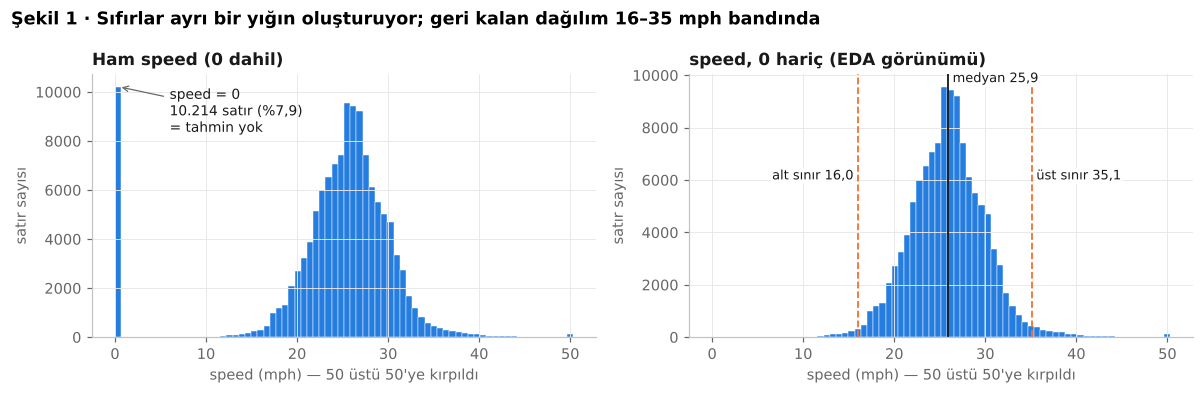

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
ax[0].hist(df["speed"].clip(upper=50), bins=np.arange(0, 50.5, 0.68), color=C["mavi"], edgecolor="white", linewidth=0.3)
ax[0].annotate(f"speed = 0\n{tr(sifir.sum())} satır (%{tr(sifir.mean()*100, 1)})\n= tahmin yok", xy=(0.4, sifir.sum()),
               xytext=(6, sifir.sum() * 0.82), color=C["murekkep"], fontsize=9,
               arrowprops=dict(arrowstyle="->", color=C["ikincil"], lw=0.8))
ax[0].set(title="Ham speed (0 dahil)", xlabel="speed (mph) — 50 üstü 50'ye kırpıldı", ylabel="satır sayısı")
q = ozet_tab.loc["speed (0 hariç)"]
ax[1].hist(df["hiz_gecerli"].clip(upper=50), bins=np.arange(0, 50.5, 0.68), color=C["mavi"], edgecolor="white", linewidth=0.3)
ust_y = ax[1].get_ylim()[1]
for x, etiket, ha, dx in [(q["alt sınır (Q1−1,5·ÇAA)"], f"alt sınır {tr(q['alt sınır (Q1−1,5·ÇAA)'], 1)}", "right", -0.5),
                          (q["medyan"], f"medyan {tr(q['medyan'], 1)}", "left", 0.5),
                          (q["üst sınır (Q3+1,5·ÇAA)"], f"üst sınır {tr(q['üst sınır (Q3+1,5·ÇAA)'], 1)}", "left", 0.5)]:
    ax[1].axvline(x, color=C["turuncu"] if "sınır" in etiket else C["murekkep"], lw=1.2, ls="--" if "sınır" in etiket else "-")
    ax[1].text(x + dx, ust_y * (0.97 if "medyan" in etiket else 0.6), etiket, fontsize=8.5, color=C["murekkep"], ha=ha,
               bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax[1].set(title="speed, 0 hariç (EDA görünümü)", xlabel="speed (mph) — 50 üstü 50'ye kırpıldı", ylabel="satır sayısı")
fig.suptitle("Şekil 1 · Sıfırlar ayrı bir yığın oluşturuyor; geri kalan dağılım 16–35 mph bandında", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout()
kaydet(fig, "sekil01_hiz_dagilimi")

Sol panelde 0'daki dikey çubuk dağılımın geri kalanından kopuk duruyor: 0 ile 5 mph arasında yalnızca 23 değer var. Gerçek bir
"çok yavaş trafik" durumu olsaydı 0'a doğru inen sürekli bir kuyruk görürdük. Sağ panel sıfırsız dağılım: tepe ~25 mph,
sağda uzun ve ince bir kuyruk (gece saatleri ve az okumalı tahminler — Şekil 6).

### Şekil 2 — Sıfırlar nerede ve ne zaman? (bölge × saat)

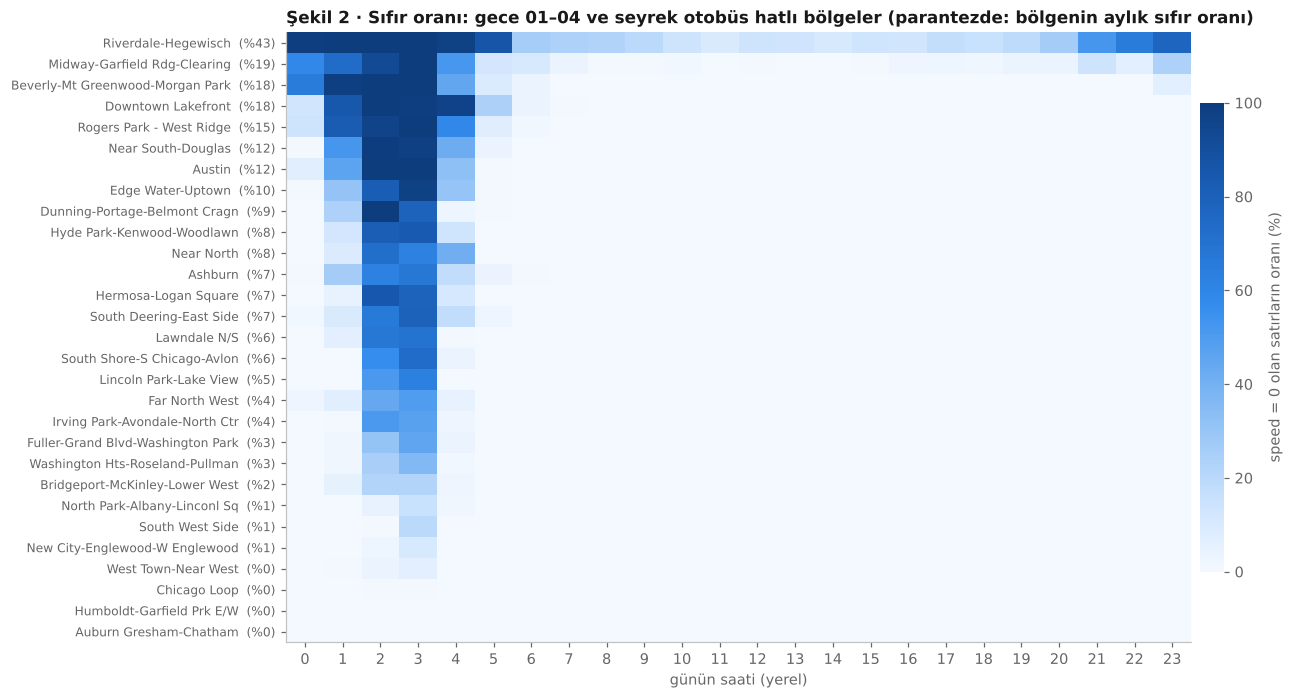

Saat başına sıfır oranı (%): {0: 9.0, 1: 23.3, 2: 55.0, 3: 58.6, 4: 19.8, 5: 5.2, 6: 1.5, 7: 1.0, 8: 0.8, 9: 0.7, 10: 0.5, 11: 0.3, 12: 0.5, 13: 0.4, 14: 0.4, 15: 0.5, 16: 0.5, 17: 0.7, 18: 0.6, 19: 0.7, 20: 1.0, 21: 2.3, 22: 2.5, 23: 3.7}


In [21]:
sifir_isi = df.assign(s0=sifir).pivot_table(index="region", columns="hour", values="s0", aggfunc="mean")
sifir_isi = sifir_isi.loc[sifir_isi.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 7.2))
im = ax.imshow(sifir_isi.values * 100, aspect="auto", cmap=MAVI_RAMPA, vmin=0, vmax=100)
ax.set_yticks(range(len(sifir_isi)), [f"{b}  (%{v*100:.0f})" for b, v in sifir_isi.mean(axis=1).items()], fontsize=8)
ax.set_xticks(range(24), range(24))
ax.set_xlabel("günün saati (yerel)"); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("speed = 0 olan satırların oranı (%)", color=C["ikincil"])
cb.outline.set_visible(False)
ax.set_title("Şekil 2 · Sıfır oranı: gece 01–04 ve seyrek otobüs hatlı bölgeler (parantezde: bölgenin aylık sıfır oranı)", loc="left")
kaydet(fig, "sekil02_sifir_orani_bolge_saat")
saat_sifir = df.assign(s0=sifir).groupby("hour")["s0"].mean()
BULGU.update(sifir_saat_maks=[int(saat_sifir.idxmax()), round(saat_sifir.max() * 100, 1)],
             sifir_bolge_maks=[sifir_isi.mean(axis=1).index[0], round(sifir_isi.mean(axis=1).iloc[0] * 100, 1)],
             sifirsiz_bolge=[b for b, v in df.assign(s0=sifir).groupby("region")["s0"].sum().items() if v == 0])
print("Saat başına sıfır oranı (%):", (saat_sifir * 100).round(1).to_dict())

Sıfırlar rastgele dağılmıyor: saat 02–03'te satırların **yarıdan fazlası** sıfır; gündüz %1'in altında. Bölge tarafında
Riverdale-Hegewisch (%43) başta — şehrin güney ucunda, otobüs hattı seyrek bir sanayi bölgesi. Humboldt-Garfield Park ve
Auburn Gresham-Chatham'da ay boyunca **hiç** sıfır yok; Chicago Loop'ta yalnızca 2. Bu desen §8'deki eksiklik mekanizması tartışmasının kanıtıdır.

### Şekil 3 — Bölgeler arası fark (0 hariç)

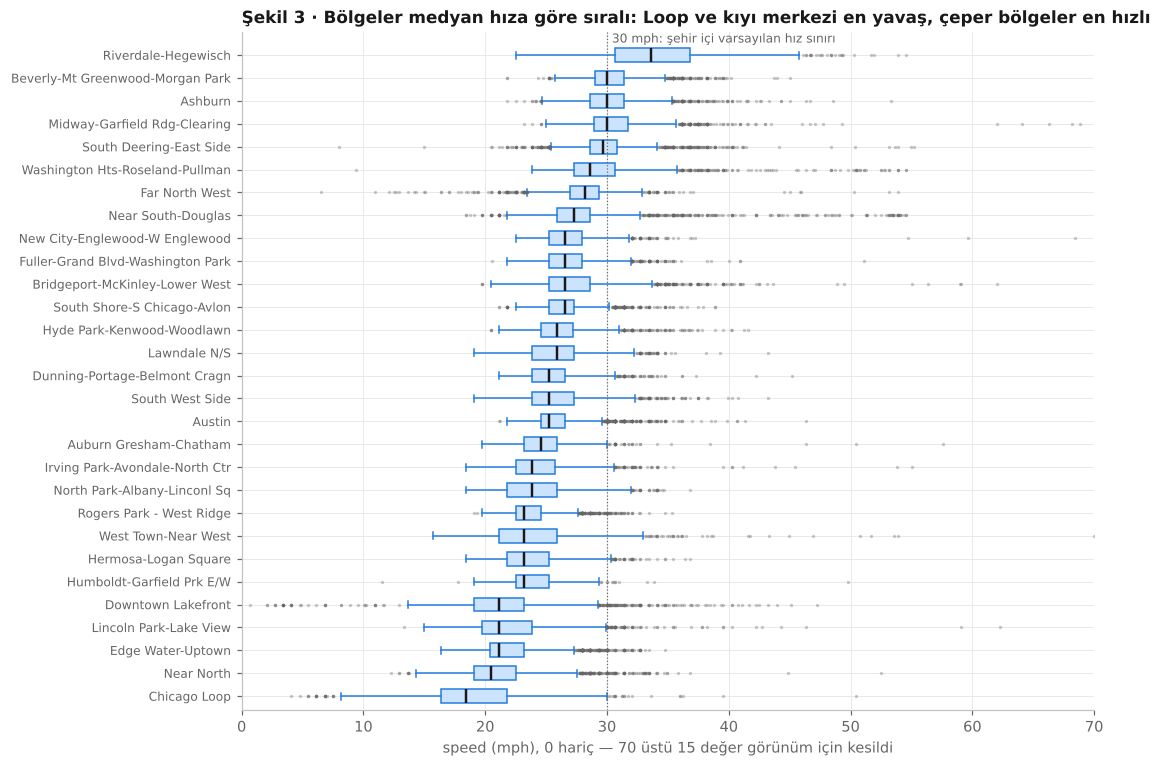

In [22]:
sira = bolge_ozet.sort_values("medyan")["region"].tolist()
veri = [df.loc[df["region"].eq(b), "hiz_gecerli"].dropna().values for b in sira]
fig, ax = plt.subplots(figsize=(10, 8))
yon = {"orientation": "horizontal"} if tuple(int(x) for x in mpl.__version__.split(".")[:2]) >= (3, 10) else {"vert": False}
bp = ax.boxplot(veri, **yon, widths=0.6, patch_artist=True, whis=1.5,
                medianprops=dict(color=C["murekkep"], lw=1.6), boxprops=dict(facecolor="#cce3fd", edgecolor=C["mavi"], lw=1),
                whiskerprops=dict(color=C["mavi"], lw=1), capprops=dict(color=C["mavi"], lw=1),
                flierprops=dict(marker="o", markersize=2.2, markerfacecolor=C["ikincil"], markeredgecolor="none", alpha=0.35))
ax.set_yticks(range(1, len(sira) + 1), sira, fontsize=8)
ax.set_xlim(0, 70); ax.set_xlabel(f"speed (mph), 0 hariç — 70 üstü {int((df['hiz_gecerli'] > 70).sum())} değer görünüm için kesildi")
ax.axvline(30, color=C["ikincil"], lw=0.8, ls=":"); ax.text(30.4, len(sira) + 0.55, "30 mph: şehir içi varsayılan hız sınırı", fontsize=8, color=C["ikincil"])
ax.set_ylim(0.4, len(sira) + 1)
ax.set_title("Şekil 3 · Bölgeler medyan hıza göre sıralı: Loop ve kıyı merkezi en yavaş, çeper bölgeler en hızlı", loc="left")
kaydet(fig, "sekil03_bolge_kutu")
BULGU["kirpilan_70"] = int((df["hiz_gecerli"] > 70).sum())

Merkez (Chicago Loop, Near North, Downtown Lakefront) belirgin biçimde yavaş; güney ve batı çeperi hızlı. Bölgeler arası fark,
bölge içi farktan büyük — bu yüzden **"tek bir şehir geneli eşik"** Loop'un sıradan bir öğleden sonrasını "olağandışı yavaş" diye
işaretler (§7'de sayıyla). Kutu grafiğinin noktaları (1,5·ÇAA dışı) çoğunlukla **sağda**: aykırılık daha çok hız yönünde birikiyor.
İstisna Downtown Lakefront ve Chicago Loop'un **solundaki** birkaç nokta (8 mph altı) — bunlar §7.1b'de olaylarla eşleşiyor.

### Şekil 4 — Tarih × saat: tekrar eden desen

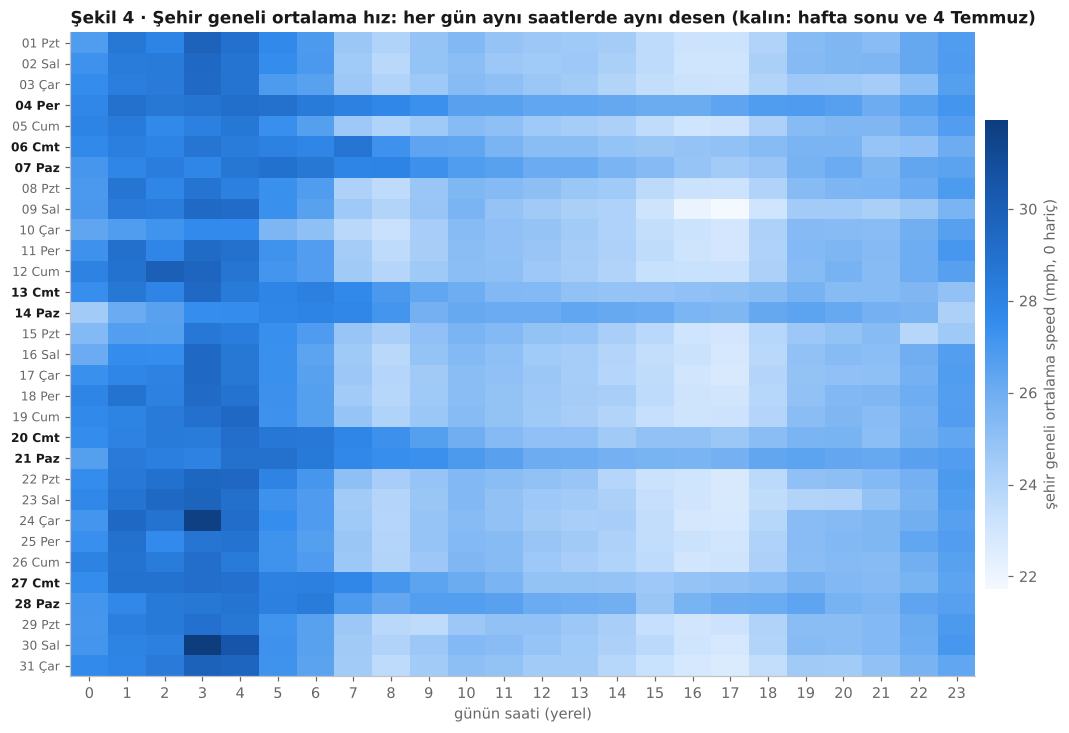

In [23]:
sehir_saat = df.groupby([df["time"].dt.date.rename("tarih"), "hour"])["hiz_gecerli"].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 7.6))
im = ax.imshow(sehir_saat.values, aspect="auto", cmap=MAVI_RAMPA)
etiket = [f"{pd.Timestamp(t).day:02d} {GUN_TR[pd.Timestamp(t).dayofweek]}" for t in sehir_saat.index]
ax.set_yticks(range(len(etiket)), etiket, fontsize=8)
for i, t in enumerate(sehir_saat.index):
    if pd.Timestamp(t).dayofweek >= 5 or pd.Timestamp(t) == pd.Timestamp("2024-07-04"):
        ax.get_yticklabels()[i].set_fontweight("bold"); ax.get_yticklabels()[i].set_color(C["murekkep"])
ax.set_xticks(range(24), range(24)); ax.set_xlabel("günün saati (yerel)"); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("şehir geneli ortalama speed (mph, 0 hariç)", color=C["ikincil"]); cb.outline.set_visible(False)
ax.set_title("Şekil 4 · Şehir geneli ortalama hız: her gün aynı saatlerde aynı desen (kalın: hafta sonu ve 4 Temmuz)", loc="left")
kaydet(fig, "sekil04_tarih_saat_isi")

Isı haritası dikey şeritlerden oluşuyor: **gece hızlı, 16–18 arası yavaş**, her gün. Kalın etiketli satırlar (hafta sonları ve
4 Temmuz) sabah saatlerinde belirgin biçimde daha açık renkte — sabah zirvesi yok. Bu, l3 varyantının sorununun ta kendisi:
ham hız üzerinde "olağandışı hızlı saat" ararsanız **her gece** ve **her hafta sonu sabahı** bulursunuz. Bu bir anomali değil,
tekrar eden düzenli desendir. (Bunu hesaba katan ön adımın seçimi 8. adımın işi.)

Desenin dışına taşan birkaç hücre de şimdiden göze çarpıyor: **9 Temmuz 16–17** ayın en açık (en yavaş) hücreleri — Beryl
kalıntılarının yağışıyla aynı akşam; **15 Temmuz 22:00** belirgin biçimde açık — derecho gecesi; **24 ve 30 Temmuz 03:00** ise ayın en
koyu hücreleri — ama bunlar §7.1'deki az okumalı gürültü. Yani bu ısı haritasında hem gerçek olaylar hem ölçüm hataları "olağandışı"
görünüyor; ikisini ayırmanın yolu §7'de.

### Şekil 5 — Ortalama günlük profil: hafta içi ↔ hafta sonu ↔ 4 Temmuz

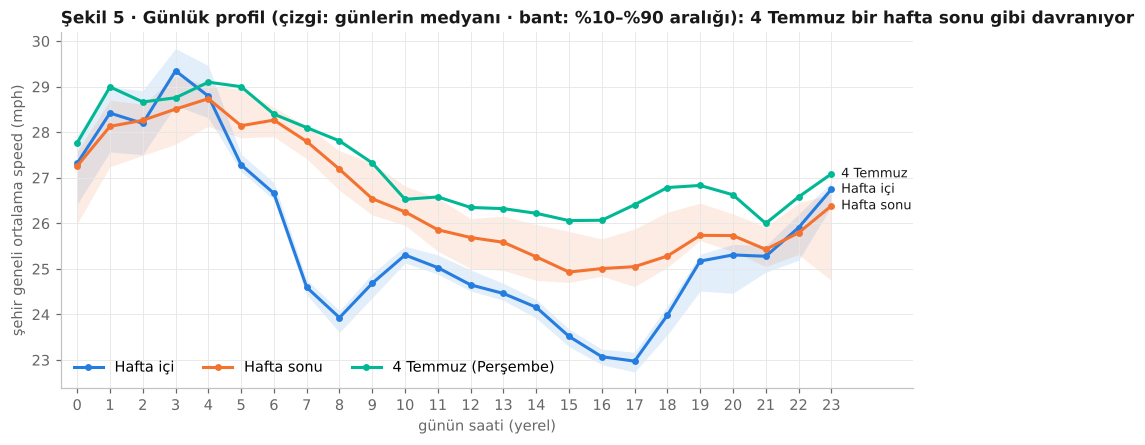

In [24]:
gun = df["time"].dt.normalize()
tip = np.where(gun.eq(pd.Timestamp("2024-07-04")), "4 Temmuz (Perşembe)",
               np.where(df["day_of_week"].isin([1, 7]), "Hafta sonu", "Hafta içi"))
profil_gun = df.assign(tip=tip, gun=gun).groupby(["tip", "gun", "hour"])["hiz_gecerli"].mean().reset_index()
fig, ax = plt.subplots(figsize=(10, 4.2))
renk = {"Hafta içi": C["mavi"], "Hafta sonu": C["turuncu"], "4 Temmuz (Perşembe)": C["turkuaz"]}
for t in ["Hafta içi", "Hafta sonu", "4 Temmuz (Perşembe)"]:
    p = profil_gun[profil_gun["tip"].eq(t)].groupby("hour")["hiz_gecerli"]
    m = p.median()
    ax.plot(m.index, m.values, color=renk[t], label=t, marker="o", markersize=3.5)
    if t != "4 Temmuz (Perşembe)":
        ax.fill_between(m.index, p.quantile(0.1), p.quantile(0.9), color=renk[t], alpha=0.13, linewidth=0)
    ax.text(23.3, m.values[-1], t.split(" (")[0], color=C["murekkep"], fontsize=8.5, va="center")
ax.set_xticks(range(24)); ax.set_xlim(-0.5, 25.5)
ax.set(xlabel="günün saati (yerel)", ylabel="şehir geneli ortalama speed (mph)")
ax.legend(loc="lower left", ncol=3)
ax.set_title("Şekil 5 · Günlük profil (çizgi: günlerin medyanı · bant: %10–%90 aralığı): 4 Temmuz bir hafta sonu gibi davranıyor", loc="left")
kaydet(fig, "sekil05_gunluk_profil")

Hafta içi eğrisinin iki çukuru var: sabah 7–8 ve akşam 16–17. Hafta sonu eğrisinde sabah çukuru yok. **4 Temmuz Perşembe**
eğrisi hafta içinden çok hafta sonuna benziyor — gerçek bir takvim olayının veride görünür izi. Hafta içi bandının darlığı, bu
desenin ne kadar düzenli tekrar ettiğini gösteriyor; bant dışına çıkan saatler 8. adımın aday olaylarıdır.

### Şekil 6 — Güvenilirlik: az okuma → oynak tahmin

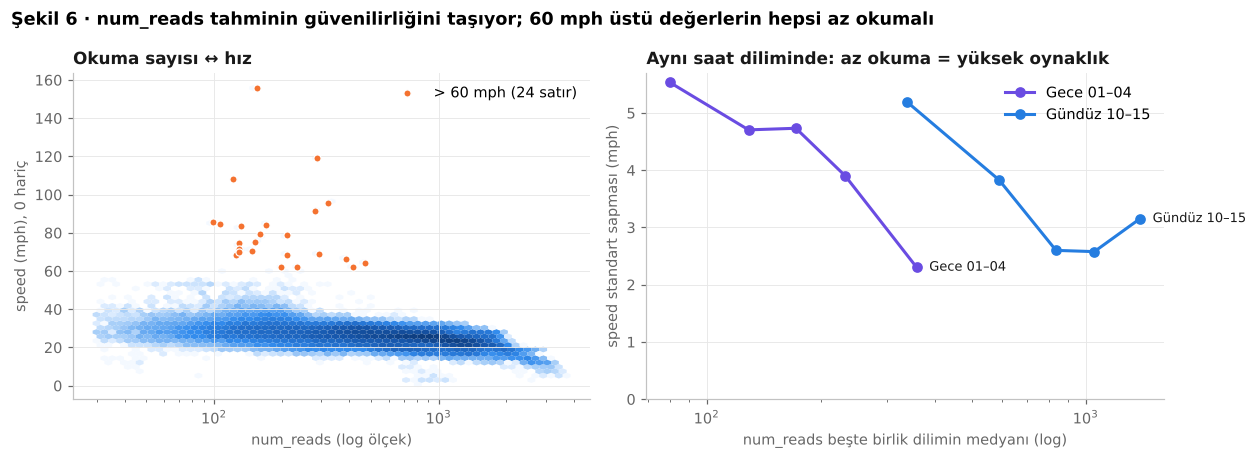

              0    1    2    3    4
gece_std   5.53 4.70 4.73 3.90 2.30
gunduz_std 5.20 3.83 2.60 2.58 3.15


In [25]:
g = df.loc[gec].copy()
g["okuma_dilimi"] = pd.qcut(g["num_reads"], 10)
gece = g[g["hour"].between(1, 4)]; gunduz = g[g["hour"].between(10, 15)]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
hb = ax[0].hexbin(g["num_reads"], g["hiz_gecerli"], gridsize=60, xscale="log", bins="log", cmap=MAVI_RAMPA, mincnt=1, linewidths=0)
cok = g[g["hiz_gecerli"] > 60]
ax[0].scatter(cok["num_reads"], cok["hiz_gecerli"], s=22, color=C["turuncu"], edgecolor="white", linewidth=0.8, zorder=3, label=f"> 60 mph ({len(cok)} satır)")
ax[0].legend(loc="upper right")
ax[0].set(xlabel="num_reads (log ölçek)", ylabel="speed (mph), 0 hariç", title="Okuma sayısı ↔ hız")
for ad, alt, r_ in [("Gece 01–04", gece, C["mor"]), ("Gündüz 10–15", gunduz, C["mavi"])]:
    s = alt.groupby(pd.qcut(alt["num_reads"], 5), observed=True)["hiz_gecerli"].std()
    x = alt.groupby(pd.qcut(alt["num_reads"], 5), observed=True)["num_reads"].median()
    ax[1].plot(x.values, s.values, marker="o", color=r_, label=ad)
    ax[1].text(x.values[-1] * 1.08, s.values[-1], ad, fontsize=8.5, color=C["murekkep"], va="center")
ax[1].set_xscale("log"); ax[1].set_ylim(0, None)
ax[1].set(xlabel="num_reads beşte birlik dilimin medyanı (log)", ylabel="speed standart sapması (mph)", title="Aynı saat diliminde: az okuma = yüksek oynaklık")
ax[1].legend(loc="upper right")
fig.suptitle("Şekil 6 · num_reads tahminin güvenilirliğini taşıyor; 60 mph üstü değerlerin hepsi az okumalı", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout()
kaydet(fig, "sekil06_guvenilirlik")
std_tab = pd.DataFrame({
    "gece_std": gece.groupby(pd.qcut(gece["num_reads"], 5), observed=True)["hiz_gecerli"].std().round(2).values,
    "gunduz_std": gunduz.groupby(pd.qcut(gunduz["num_reads"], 5), observed=True)["hiz_gecerli"].std().round(2).values})
print(std_tab.T)
BULGU.update(std_gece_az=float(std_tab["gece_std"].iloc[0]), std_gece_cok=float(std_tab["gece_std"].iloc[-1]),
             std_gunduz_az=float(std_tab["gunduz_std"].iloc[0]), std_gunduz_cok=float(std_tab["gunduz_std"].iloc[-1]))

Sol panel bir huni: okuma sayısı azaldıkça hız değerleri yukarı doğru saçılıyor; 60 mph'yi aşan 24 değerin **hepsi** huninin
geniş ucunda. Ama dikkat — az okuma genellikle gece olur, gece de trafik gerçekten hızlıdır. Bu karışıklığı ayırmak için sağ panel
**aynı saat dilimi içinde** bakıyor: gece de gündüz de okuma azaldıkça standart sapma büyüyor (gece 5,5 → 2,3 mph; gündüz 5,2 → 2,6).
Yani oynaklık yalnızca "gece etkisi" değil, **ölçümün kendisinin** az veriye dayanmasından da geliyor. Gündüzün en çok okumalı
diliminde std'nin yeniden hafifçe yükselmesi (3,2) beklenen bir şey: o dilim Loop gibi yoğun bölgelerden oluşuyor ve oradaki oynaklık
ölçümden değil, **gerçek tıkanıklıktan** geliyor.

### Şekil 7 — Ay boyunca zaman serisi (ön gözlem)

İki ayrı panel — iki farklı ölçü tek eksene sıkıştırılmıyor.

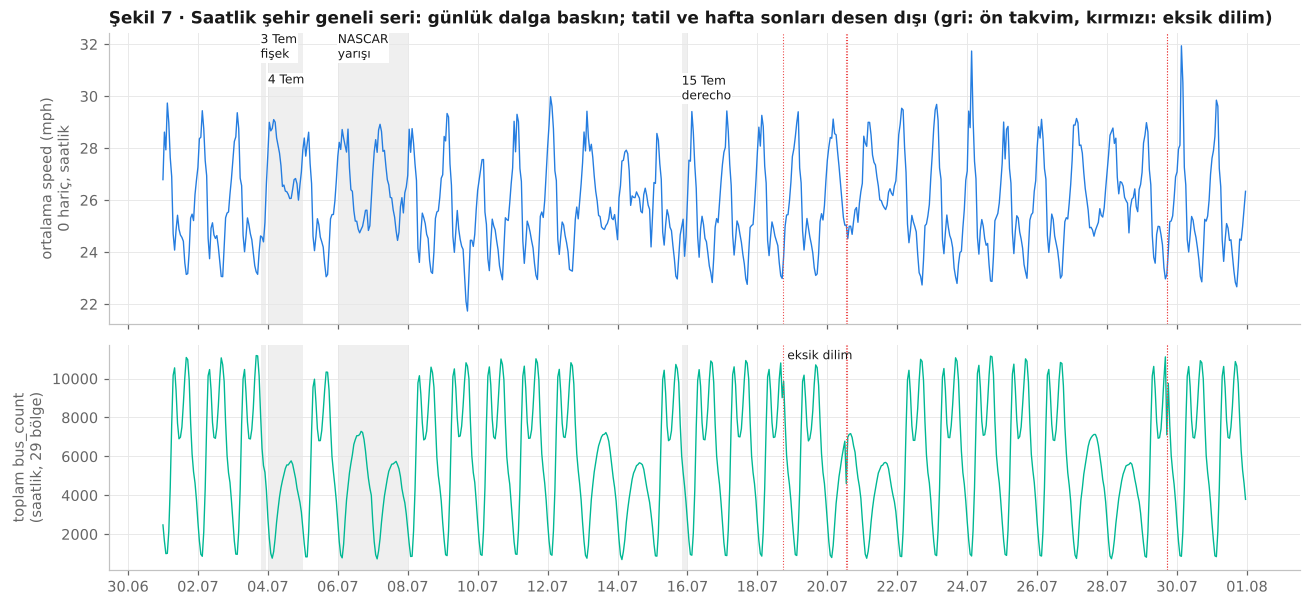

In [26]:
saatlik = df.groupby(df["time"].dt.floor("h")).agg(hiz=("hiz_gecerli", "mean"), otobus=("bus_count", "sum"))
olay_bantlari = [("2024-07-03 19:00", "2024-07-03 23:00", "3 Tem\nfişek"), ("2024-07-04", "2024-07-05", "4 Tem"), ("2024-07-06", "2024-07-08", "NASCAR\nyarışı"),
                 ("2024-07-15 20:00", "2024-07-16 00:00", "15 Tem\nderecho")]
fig, ax = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax[0].plot(saatlik.index, saatlik["hiz"], color=C["mavi"], lw=0.9)
ax[0].set_ylabel("ortalama speed (mph)\n0 hariç, saatlik")
ax[1].plot(saatlik.index, saatlik["otobus"], color=C["turkuaz"], lw=0.9)
ax[1].set_ylabel("toplam bus_count\n(saatlik, 29 bölge)")
for a in ax:
    for b, s_, ad in olay_bantlari:
        a.axvspan(pd.Timestamp(b), pd.Timestamp(s_), color=C["notr"], zorder=0, lw=0)
    for t in eksik_dilim:
        a.axvline(t, color=C["kirmizi"], lw=0.7, ls=":")
for k, (b, s_, ad) in enumerate(olay_bantlari):
    y = ax[0].get_ylim()[1] - (0.0 if k % 2 == 0 else 1.6)
    ax[0].text(pd.Timestamp(b), y, ad, fontsize=8, va="top", color=C["murekkep"], bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
ax[1].text(eksik_dilim[0], ax[1].get_ylim()[1] * 0.98, " eksik dilim", color=C["murekkep"], fontsize=8, va="top")
ax[1].xaxis.set_major_locator(mpl.dates.DayLocator(interval=2)); ax[1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%d.%m"))
ax[0].set_title("Şekil 7 · Saatlik şehir geneli seri: günlük dalga baskın; tatil ve hafta sonları desen dışı (gri: ön takvim, kırmızı: eksik dilim)", loc="left")
fig.tight_layout()
kaydet(fig, "sekil07_zaman_serisi")

Üst panelde günlük dalga o kadar baskın ki tek tek olaylar gözle zor seçiliyor — ham seride "olağandışı" aramanın neden yanıltıcı
olacağının bir başka görüntüsü. 24 ve 30 Temmuz gecelerindeki sivri tepeler gerçek bir hızlanma değil: §7.1'deki az okumalı
60 mph üstü değerler şehir ortalamasını tek başına yukarı çekiyor. 9 Temmuz akşamındaki en derin çukur ise Beryl kalıntılarının
getirdiği yağışla aynı akşama denk geliyor (§9). Alt panel bir şeyi daha gösteriyor: **otobüs sayısı da takvime tepki veriyor** (4 Temmuz ve hafta
sonları daha az sefer). Yani olay günlerinde yalnızca trafik değil, **ölçüm aracının kendisi** de değişiyor. Gri bantlar
takvimden gelen ön listedir (§9); burada doğrulama yapılmıyor.

### Şekil 8 — Ölçüm aracı olaydan etkileniyor: Downtown Lakefront

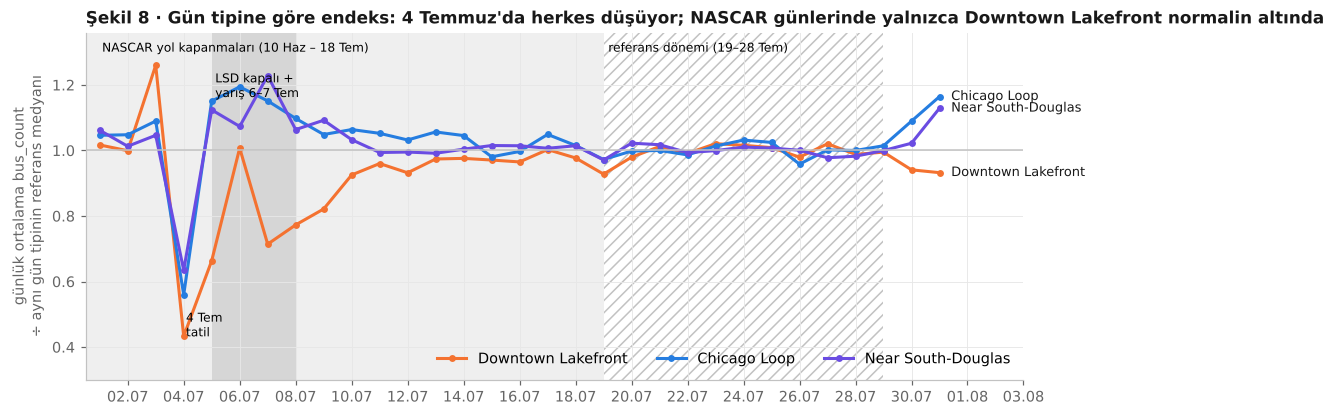

gun                 2024-07-03  2024-07-04  2024-07-05  2024-07-06  2024-07-07  2024-07-08  2024-07-09  2024-07-10
region                                                                                                            
Downtown Lakefront        1.26        0.43        0.66        1.01        0.71        0.77        0.82        0.93
Chicago Loop              1.09        0.56        1.15        1.19        1.15        1.10        1.05        1.06
Near South-Douglas        1.05        0.63        1.12        1.07        1.23        1.06        1.09        1.03
Referans medyanları:
 region     Downtown Lakefront  Chicago Loop  Near South-Douglas
Cumartesi               20.00         47.60               23.80
Hafta içi               32.40         73.70               30.70
Pazar                   15.00         39.10               19.40


In [27]:
gunluk_bus = df.groupby([df["time"].dt.normalize().rename("gun"), "region"])["bus_count"].mean().unstack()
gun_tipi = pd.Series(np.where(gunluk_bus.index.dayofweek == 5, "Cumartesi",
                              np.where(gunluk_bus.index.dayofweek == 6, "Pazar", "Hafta içi")), index=gunluk_bus.index)
referans = gunluk_bus.loc["2024-07-19":"2024-07-28"]           # iki etkinliğin büyük kapanmalarından arınmış 10 gün
ref_med = referans.groupby(gun_tipi.loc[referans.index]).median()
endeks = gunluk_bus / ref_med.loc[gun_tipi].set_index(gunluk_bus.index)
fig, ax = plt.subplots(figsize=(11, 4.1))
for b, r_ in [("Downtown Lakefront", C["turuncu"]), ("Chicago Loop", C["mavi"]), ("Near South-Douglas", C["mor"])]:
    ax.plot(endeks.index, endeks[b], color=r_, marker="o", markersize=3.5, label=b)
    ax.text(endeks.index[-1] + pd.Timedelta(hours=10), endeks[b].iloc[-1], b, fontsize=8.5, va="center", color=C["murekkep"])
ax.axhline(1, color=C["eksen"], lw=1)
ax.axvspan(pd.Timestamp("2024-06-30 12:00"), pd.Timestamp("2024-07-18 23:59"), color=C["notr"], zorder=0, lw=0)
ax.axvspan(pd.Timestamp("2024-07-05 00:00"), pd.Timestamp("2024-07-07 23:59"), color="#d6d6d6", zorder=0, lw=0)
ax.axvspan(pd.Timestamp("2024-07-19 00:00"), pd.Timestamp("2024-07-28 23:59"), facecolor="none", edgecolor=C["eksen"], hatch="///", lw=0, zorder=0)
ax.text(pd.Timestamp("2024-07-01 02:00"), 1.33, "NASCAR yol kapanmaları (10 Haz – 18 Tem)", fontsize=8, va="top")
ax.text(pd.Timestamp("2024-07-05 03:00"), 1.24, "LSD kapalı +\nyarış 6–7 Tem", fontsize=8, va="top")
ax.text(pd.Timestamp("2024-07-19 04:00"), 1.33, "referans dönemi (19–28 Tem)", fontsize=8, va="top")
ax.text(pd.Timestamp("2024-07-04 02:00"), 0.42, "4 Tem\ntatil", fontsize=8, va="bottom")
ax.set_ylim(0.3, 1.36); ax.set_xlim(pd.Timestamp("2024-06-30 12:00"), pd.Timestamp("2024-08-03"))
ax.xaxis.set_major_locator(mpl.dates.DayLocator(interval=2)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%d.%m"))
ax.set_ylabel("günlük ortalama bus_count\n÷ aynı gün tipinin referans medyanı"); ax.legend(loc="lower right", ncol=3)
ax.set_title("Şekil 8 · Gün tipine göre endeks: 4 Temmuz'da herkes düşüyor; NASCAR günlerinde yalnızca Downtown Lakefront normalin altında", loc="left")
kaydet(fig, "sekil08_downtown_otobus")
dl = endeks["Downtown Lakefront"]
BULGU.update(dl_endeks={d.strftime("%m-%d"): round(float(v), 2) for d, v in dl.loc["2024-07-03":"2024-07-10"].items()},
             loop_endeks_0705=round(float(endeks.loc["2024-07-05", "Chicago Loop"]), 2),
             ns_endeks_0705=round(float(endeks.loc["2024-07-05", "Near South-Douglas"]), 2),
             dl_bus_4_7=gunluk_bus.loc["2024-07-04":"2024-07-07", "Downtown Lakefront"].round(1).tolist(),
             dl_bus_hafta_ici_medyan=round(float(ref_med.loc["Hafta içi", "Downtown Lakefront"]), 1))
print(endeks.loc["2024-07-03":"2024-07-10", ["Downtown Lakefront", "Chicago Loop", "Near South-Douglas"]].round(2).T)
print("Referans medyanları:\n", ref_med[["Downtown Lakefront", "Chicago Loop", "Near South-Douglas"]].round(1))

Ham otobüs sayısı hafta sonu ve tatilde her bölgede düşer; bu yüzden her günü **aynı gün tipinin** (hafta içi / cumartesi / pazar)
referans medyanına bölüyoruz (referans: 19–28 Temmuz, iki etkinliğin büyük kapanmalarının dışında kalan 10 gün). 1,0 = "bu gün tipi
için normal".

Downtown Lakefront (Roosevelt–Oak, Michigan–Lake Shore) NASCAR parkurunun, Grant Park'ın ve Navy Pier'in bulunduğu bölge.
4 Temmuz'da üç bölge birlikte düşüyor — bu tatilin etkisi. Ama **5 Temmuz Cuma** (Lake Shore Drive'ın tam kapandığı gün) Loop ve
Near South normalin üstüne çıkarken Downtown Lakefront normalinin **%66'sında** kalıyor; 7 Temmuz (yarış pazarı) 0,71, ardından gelen
8–9 Temmuz 0,77 ve 0,82. (6 Temmuz cumartesi ise 1,01 — normal; 3 Temmuz havai fişek gününde 1,26.) Ay sonunda (30–31 Temmuz)
Lollapalooza kapanmaları başlarken aynı ayrışma küçük ölçekte yeniden beliriyor: Downtown Lakefront 1'in altına inerken Loop yükseliyor.

> 🔗 **H02 vaka notuyla bağlantı.** Google Grip Eğilimleri'nde makalenin adlandırdığı ikinci tuzak *algoritma dinamikleriydi*: ölçüm
> aracının kendisi değişince model neyi ölçtüğünü bilmez hâle geldi. Burada da olay günlerinde **ölçüm aracı değişiyor** — otobüsler
> güzergâh değiştiriyor, bölgedeki okuma sayısı düşüyor. 8. adımda bir olay gününün "olağandışı" hızını yorumlarken bu yazılmalı. Kapanmalar ve güzergâh değişiklikleri otobüsleri bölgeden çıkarınca, hız tahmini **daha az veriye** dayanıyor. 8. adım için önemli
sonuç: bir olay günündeki "olağandışı" değer kısmen trafikten, kısmen ölçüm kalitesinden gelebilir — `bus_count` ve `num_reads`
bu ayrımı yapmak için tutulmalı.

## 7 · Aykırı değer araştırması

3. adım aykırı değerlere bir temizlik kararı olarak bakacak; 8. adım ise bir **bulgu** olarak. Burada yalnızca **taranıyor ve
sınıflanıyor**: hangi değerler, hangi kuralla, nerede işaretleniyor — ve işaretlenen şey hata mı, desen mi, olay mı?

### 7.1 Fiziksel makullük

H03'ün ilk sorusu: *"Fiziksel olarak mümkün mü?"* `speed` bir bölgenin **bütün arter yollarının** ortalaması; Chicago'nun şehir içi
varsayılan hız sınırı 30 mph. Bir bölge ortalamasının bunun iki katını (60 mph ≈ 97 km/sa) aşması, bölgedeki bütün araçların
her yerde sınırın iki katıyla gittiğini söylemek olur.

In [28]:
esikler = pd.DataFrame([{"eşik": f"> {e} mph", "satır": int((df["speed"] > e).sum()),
                         "medyan bus_count": df.loc[df["speed"] > e, "bus_count"].median(),
                         "medyan num_reads": df.loc[df["speed"] > e, "num_reads"].median(),
                         "gece 00–05 payı": f"%{(df.loc[df['speed'] > e, 'hour'] <= 5).mean()*100:.0f}"}
                        for e in [35.1, 45, 60]])
esikler.loc[len(esikler)] = {"eşik": "tüm geçerli satırlar", "satır": int(gec.sum()),
                             "medyan bus_count": df.loc[gec, "bus_count"].median(), "medyan num_reads": df.loc[gec, "num_reads"].median(),
                             "gece 00–05 payı": f"%{(df.loc[gec, 'hour'] <= 5).mean()*100:.0f}"}
display(esikler)
imkansiz = df.loc[df["speed"] > 60, ["time", "region", "speed", "bus_count", "num_reads"]].sort_values("speed", ascending=False)
imkansiz.to_csv(OUT / "aykiri_60mph_ustu.csv", index=False, encoding="utf-8-sig")
display(imkansiz)
BULGU.update(ust45=int((df["speed"] > 45).sum()), ust60=int((df["speed"] > 60).sum()),
             ust60_maks_bus=int(imkansiz["bus_count"].max()), ust60_maks_reads=int(imkansiz["num_reads"].max()),
             ust60_gun=int(imkansiz["time"].dt.date.nunique()))

,eşik,satır,medyan bus_count,medyan num_reads,gece 00–05 payı
0,> 35.1 mph,2120,7.00,154.00,%42
1,> 45 mph,191,7.00,135.00,%77
2,> 60 mph,24,7.50,165.50,%71
3,tüm geçerli satırlar,119097,32.00,629.00,%19


,time,region,speed,bus_count,num_reads
121657,2024-07-30 04:01:07,North Park-Albany-Linconl Sq,155.80,7,155
22251,2024-07-06 07:50:33,Austin,119.18,13,287
121686,2024-07-30 04:10:21,North Park-Albany-Linconl Sq,108.41,7,121
22106,2024-07-06 07:01:19,Austin,95.80,15,322
88582,2024-07-22 05:31:04,Midway-Garfield Rdg-Clearing,91.36,9,283
121557,2024-07-30 03:20:35,New City-Englewood-W Englewood,85.43,7,99
121582,2024-07-30 03:30:51,Bridgeport-McKinley-Lower West,84.55,7,106
96334,2024-07-24 02:01:07,Washington Hts-Roseland-Pullman,84.20,7,171
96559,2024-07-24 03:20:35,New City-Englewood-W Englewood,83.42,6,132
16770,2024-07-05 00:20:42,Austin,79.30,8,160


60 mph üstü 24 değer (en yüksek 155,8 mph — 250 km/sa): hepsinde `bus_count` ≤ 19 ve `num_reads` ≤ 471, yani geçerli satırların
medyanının (32 otobüs, 629 okuma) altında; %71'i gece 00–05. Aynı gece birden çok komşu bölgede birlikte çıkıyorlar (24 ve 30 Temmuz 01–04):
birkaç hızlı otobüsün az veriyle bütün bölgenin tahminini sürüklediği bir **ölçüm gürültüsü** görüntüsü. Bunlar "olağandışı hızlı
saat" olarak 8. adımın listesine girerse ilk yanlış alarmlar bunlar olur.

### 7.1b Yavaş uç: 8 mph altı — ama bu kez otobüs çok

Hızlı uçtaki imkânsız değerler az okumalıydı. Yavaş uca bakalım: 8 mph (~13 km/sa) altındaki geçerli değerler.

In [29]:
yavas = df[(df["speed"] > 0) & (df["speed"] < 8)].copy()
yavas["tarih"] = yavas["time"].dt.date
bolum = (yavas.groupby(["region", "tarih"])
         .agg(satir=("speed", "size"), ilk=("time", "min"), son=("time", "max"), min_hiz=("speed", "min"),
              medyan_bus=("bus_count", "median"), medyan_okuma=("num_reads", "median"))
         .reset_index().sort_values("ilk"))
bolum["ilk"] = bolum["ilk"].dt.strftime("%H:%M"); bolum["son"] = bolum["son"].dt.strftime("%H:%M")
bolum.to_csv(OUT / "aykiri_8mph_alti_bolumler.csv", index=False, encoding="utf-8-sig")
display(bolum)
print(f"8 mph altı geçerli satır: {len(yavas)} · bunların {int((yavas['bus_count'] >= 40).sum())}'inde bus_count ≥ 40")
BULGU.update(alt8=len(yavas), alt8_cok_otobus=int((yavas["bus_count"] >= 40).sum()), alt5=int(((df["speed"] > 0) & (df["speed"] < 5)).sum()))

,region,tarih,satir,ilk,son,min_hiz,medyan_bus,medyan_okuma
2,Downtown Lakefront,2024-07-03,17,19:31,22:31,0.68,66.00,973.00
0,Chicago Loop,2024-07-05,8,16:01,17:40,6.14,195.50,"3,136.50"
3,Downtown Lakefront,2024-07-06,10,21:01,22:50,2.05,48.00,807.00
5,South Deering-East Side,2024-07-20,1,03:40,03:40,7.98,5.00,47.00
4,Far North West,2024-07-31,1,01:30,01:30,6.48,12.00,86.00
1,Chicago Loop,2024-07-31,14,17:10,19:21,4.09,187.50,"3,046.00"


8 mph altı geçerli satır: 51 · bunların 49'inde bus_count ≥ 40


Tablo, hızlı uçtakinin tam tersini söylüyor: bu değerlerin neredeyse hepsi **40–230 otobüs ve yüzlerce–binlerce okumayla** ölçülmüş.
Az veriyle sürüklenmiş bir tahmin değil, çok veriyle ölçülmüş bir **durma**. Ve hepsi birkaç saatlik bölümler hâlinde geliyor:

| Bölüm | Ölçülen | Takvimde ne var? (ön eşleştirme) | Düzey |
|---|---|---|---|
| 3 Tem (Çar) 19:30–22:30 · Downtown Lakefront | 0,68–6,8 mph, 55–75 otobüs | Navy Pier'in Bağımsızlık Günü havai fişek gösterisi, saat 21:00 (şehrin ana gösterisi bu yıl 3 Temmuz'daydı); Navy Pier bu bölgenin içinde | ✓ |
| 5 Tem (Cum) 16:00–17:40 · Chicago Loop | 6,1–7,5 mph, ~190–210 otobüs | O gün 00:01'de DuSable Lake Shore Drive iki yönde kapandı (NASCAR) + uzun hafta sonu çıkışı. Olası açıklama | 🟡 |
| 6 Tem (Cmt) 21:00–22:50 · Downtown Lakefront | 2,1–6,8 mph, 42–53 otobüs | NASCAR yarış günü, Grant Park'ta akşam konseri (The Chainsmokers) + Navy Pier cumartesi havai fişeği (22:00) | ✓ |
| 31 Tem (Çar) 17:10–19:20 · Chicago Loop | 4,1–7,5 mph, 134–230 otobüs | Lollapalooza'nın son kapanmaları (Monroe 31 Tem) — ama doğrudan bir açıklama bulunamadı | ❓ 8. adımda |
| 2 tekil değer (gece, 5–12 otobüs) | 6,5–8,0 mph | Az okumalı gürültü | — |

🔑 **Aynı "aykırı" etiketi, iki zıt teşhis.** Hızlı uçtaki uçlar az okumalı **gürültü**, yavaş uçtaki uçlar çok okumalı **olay**.
İkisini ayıran şey hız değil, `bus_count` / `num_reads`. Bu, H03 §3.4'ün sorusunun bu veriye özgü cevabıdır: *"Aykırı değer mi,
yoksa cevabın kendisi mi?"* — l3'te aranan şey tam olarak bu ikinci gruptur, temizlik sırasında **silinmemelidir**.

### 7.2 Şehir geneli kurallar: 1,5 × ÇAA ↔ z-skoru

In [30]:
s = df["hiz_gecerli"]
q1, q3 = s.quantile([0.25, 0.75]); caa = q3 - q1
caa_alt, caa_ust = s < q1 - 1.5 * caa, s > q3 + 1.5 * caa
z = (s - s.mean()) / s.std()
z_alt, z_ust = z < -3, z > 3
merkez = df["region"].isin(["Chicago Loop", "Near North", "Downtown Lakefront"])
gece_m = df["hour"] <= 5
hs = df["day_of_week"].isin([1, 7])

def kim(maske, ad):
    f = maske.fillna(False)
    return {"kural": ad, "işaretlenen": int(f.sum()),
            "merkez 3 bölge payı": f"%{merkez[f].mean()*100:.0f}", "gece 00–05 payı": f"%{gece_m[f].mean()*100:.0f}",
            "hafta sonu payı": f"%{hs[f].mean()*100:.0f}", "kaç farklı gün": int(df.loc[f, "time"].dt.date.nunique())}

ctx = {}
for anahtar, ad in [(["region_id", "hour"], "bölge × saat"), (["region_id", "hour", "hafta_sonu"], "bölge × saat × gün tipi")]:
    gg = df.assign(hafta_sonu=hs).groupby(anahtar)["hiz_gecerli"]
    Q1, Q3 = gg.transform(lambda x: x.quantile(0.25)), gg.transform(lambda x: x.quantile(0.75))
    ctx[ad] = (s < Q1 - 1.5 * (Q3 - Q1), s > Q3 + 1.5 * (Q3 - Q1))

kural_tab = pd.DataFrame([
    {"kural": "— taban oranlar (tüm geçerli satırlar)", "işaretlenen": int(gec.sum()), "merkez 3 bölge payı": f"%{merkez[gec].mean()*100:.0f}",
     "gece 00–05 payı": f"%{gece_m[gec].mean()*100:.0f}", "hafta sonu payı": f"%{hs[gec].mean()*100:.0f}", "kaç farklı gün": 31},
    kim(caa_alt, "Şehir geneli 1,5·ÇAA — yavaş uç"), kim(caa_ust, "Şehir geneli 1,5·ÇAA — hızlı uç"),
    kim(z_alt | z_ust, "Şehir geneli |z| > 3"),
    kim(ctx["bölge × saat"][0] | ctx["bölge × saat"][1], "Bağlamsal 1,5·ÇAA — bölge × saat"),
    kim(ctx["bölge × saat × gün tipi"][0] | ctx["bölge × saat × gün tipi"][1], "Bağlamsal 1,5·ÇAA — bölge × saat × gün tipi"),
])
kural_tab.to_csv(OUT / "aykiri_kural_karsilastirma.csv", index=False, encoding="utf-8-sig")
display(kural_tab)
print(f"Şehir geneli sınırlar: ÇAA [{q1 - 1.5*caa:.2f}, {q3 + 1.5*caa:.2f}] · z: ortalama {s.mean():.2f} ± 3×{s.std():.2f} = [{s.mean()-3*s.std():.2f}, {s.mean()+3*s.std():.2f}]")
print("Yavaş uçta işaretlenenlerin bölgeleri:", df.loc[caa_alt.fillna(False), "region"].value_counts().head(4).to_dict())
BULGU["kural_tab"] = kural_tab.to_dict(orient="records")
BULGU.update(z_alt=int(z_alt.sum()), z_ust=int(z_ust.sum()), caa_alt=int(caa_alt.sum()), caa_ust=int(caa_ust.sum()),
             loop_yavas=int(df.loc[caa_alt.fillna(False), "region"].eq("Chicago Loop").sum()))

,kural,işaretlenen,merkez 3 bölge payı,gece 00–05 payı,hafta sonu payı,kaç farklı gün
0,— taban oranlar (tüm geçerli satırlar),119097,%10,%19,%25,31
1,"Şehir geneli 1,5·ÇAA — yavaş uç",1171,%98,%1,%15,29
2,"Şehir geneli 1,5·ÇAA — hızlı uç",2120,%2,%42,%28,31
3,Şehir geneli |z| > 3,1019,%25,%36,%22,31
4,"Bağlamsal 1,5·ÇAA — bölge × saat",3864,%11,%21,%49,31
5,"Bağlamsal 1,5·ÇAA — bölge × saat × gün tipi",4562,%11,%18,%21,31


Şehir geneli sınırlar: ÇAA [16.02, 35.10] · z: ortalama 25.68 ± 3×4.27 = [12.86, 38.50]
Yavaş uçta işaretlenenlerin bölgeleri: {'Chicago Loop': 927, 'Near North': 113, 'Downtown Lakefront': 105, 'Far North West': 11}


**Okuma — "kimi işaretliyor?"** Tablodaki payları ilk satırdaki taban oranlarla karşılaştırın:

- **Şehir geneli ÇAA, yavaş uç:** işaretlenenlerin **%98'i** üç merkez bölgeden (taban oranları %10). Kural "olağandışı yavaş saat"
  bulmuyor; **Loop'un kendisini** buluyor (927 / 1.171). Bu yapısal bir bölge farkıdır, olay değil.
- **Şehir geneli ÇAA, hızlı uç:** işaretlenenlerin %42'si gece 00–05'te (taban %19). Kural **her geceyi** buluyor — 31 günün 31'inde.
- **z-skoru** daha az işaretliyor ama aynı karışımı taşıyor. (Büyük n'de n ↔ n−1 farkı önemsiz: n ≈ 119 bin.)
- **Bağlamsal (bölge × saat):** merkez ve gece payları tabana yaklaşıyor, ama bu kez **hafta sonu** payı %49'a fırlıyor (taban %25):
  hafta içi ile hafta sonunu aynı kaba koyunca hafta sonu sabahları "aykırı" görünüyor.
- **Bağlamsal (bölge × saat × gün tipi):** üç pay da taban oranlara yakın — işaretlemeler artık bilinen bir desenle açıklanamıyor.

🔑 **Asıl ders:** "aykırı değer" bir kuralın çıktısıdır ve kural **neye göre** aykırı olduğunu sessizce seçer. Şehir geneli kural,
tekrar eden deseni (bölge, saat, gün tipi) aykırılık sanıyor. Bu, l3'ün 🛠 satırındaki sorunun 2. adımda ilk görünüşüdür; hangi
yolun yanlış alarmı azalttığını takvimle **ölçmek** 8. adımın işi. İşaretlenen satır **sayısının** düşmemesi de bir bulgu:
bağlam eklemek "az alarm" değil, "doğru yerde alarm" sağlayabilir — bunu takvim söyleyecek.

### Şekil 9 — İşaretlemelerin saate göre dağılımı

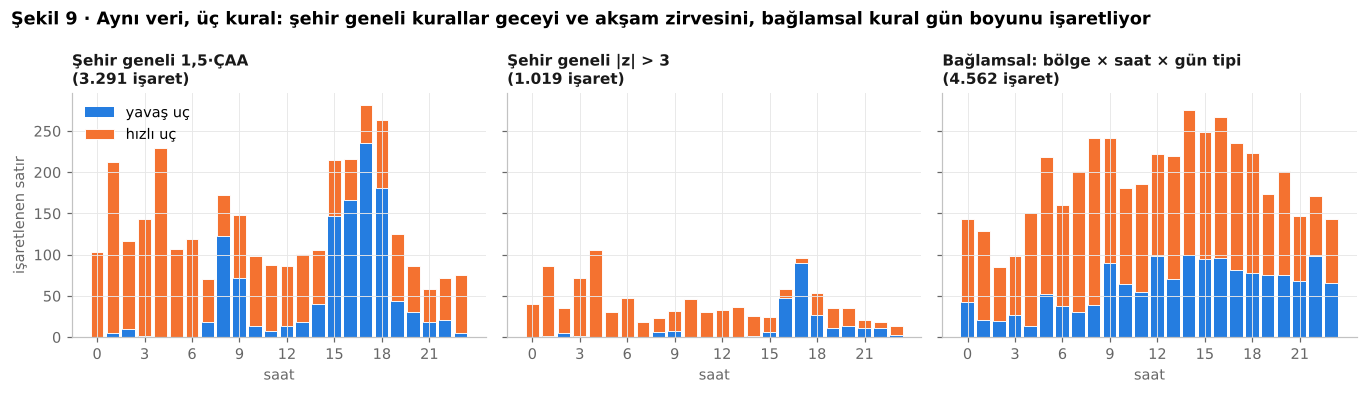

In [31]:
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
paneller = [("Şehir geneli 1,5·ÇAA", caa_alt, caa_ust), ("Şehir geneli |z| > 3", z_alt, z_ust),
            ("Bağlamsal: bölge × saat × gün tipi", *ctx["bölge × saat × gün tipi"])]
for a, (ad, lo, hi_) in zip(axs, paneller):
    lo_s = df.loc[lo.fillna(False), "hour"].value_counts().reindex(range(24), fill_value=0)
    hi_s = df.loc[hi_.fillna(False), "hour"].value_counts().reindex(range(24), fill_value=0)
    a.bar(range(24), lo_s, color=C["mavi"], width=0.8, label="yavaş uç")
    a.bar(range(24), hi_s, bottom=lo_s, color=C["turuncu"], width=0.8, label="hızlı uç", edgecolor="white", linewidth=0.6)
    a.set_title(f"{ad}\n({tr(int(lo.sum()) + int(hi_.sum()))} işaret)", fontsize=10)
    a.set_xticks(range(0, 24, 3)); a.set_xlabel("saat")
axs[0].set_ylabel("işaretlenen satır"); axs[0].legend(loc="upper left")
fig.suptitle("Şekil 9 · Aynı veri, üç kural: şehir geneli kurallar geceyi ve akşam zirvesini, bağlamsal kural gün boyunu işaretliyor",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout()
kaydet(fig, "sekil09_aykiri_kurallar")

### 7.3 `bus_count` ve `num_reads`'te aykırılık

İki sayım sütununun da ÇAA üst sınırını aşan değerleri var (bus_count > 99: 2.053 satır; num_reads > 1.984: 1.405 satır). Bunlar
Loop ve çevresinde akşam zirvesinde **gerçekten çok otobüs** olduğu anlardır — mümkün ve sık. H03 karar soruları: fiziksel olarak
mümkün mü? Evet. Nadir mi? Hayır, her hafta içi akşamı. → Hata değil.

In [32]:
for c in ["bus_count", "num_reads"]:
    ust = ozet_tab.loc[c, "üst sınır (Q3+1,5·ÇAA)"]
    f = df[c] > ust
    print(f"{c}: üst sınır {ust:,.0f} → {int(f.sum()):,} satır · bölgeler: {df.loc[f, 'region'].value_counts().head(3).to_dict()} · "
          f"en sık saatler: {df.loc[f, 'hour'].value_counts().head(3).index.tolist()}")

bus_count: üst sınır 99 → 2,053 satır · bölgeler: {'Chicago Loop': 967, 'Lincoln Park-Lake View': 548, 'West Town-Near West': 331} · en sık saatler: [16, 8, 17]
num_reads: üst sınır 1,984 → 1,405 satır · bölgeler: {'Chicago Loop': 691, 'Lincoln Park-Lake View': 487, 'West Town-Near West': 188} · en sık saatler: [8, 16, 17]


### 7.4 Özet — hata mı, desen mi, keşif mi?

| Ne işaretlendi | Kaç | Hangi kılık | Ön teşhis | Kimin kararı |
|---|---|---|---|---|
| `speed = 0` | 10.214 | Sıfır kılığında eksik | **Hata değil, eksik işareti** (okuma eşiği altında) | 3. adım: nasıl ele alınacak |
| `speed > 60 mph` | 24 | Fiziksel olarak inanılmaz | **Ölçüm gürültüsü** — az okumalı, gece | 3. adım: işaretle / ayıkla |
| `speed < 8 mph`, çok otobüslü | 49 (4 bölüm) | Şehir geneli kuralın yavaş ucu | **Gerçek olay** — havai fişek, kapanma | **Korunmalı** · 8. adımın isabet adayları |
| 45–60 mph arası | 167 | Şüpheli | Çoğu az okumalı; bir kısmı gerçek serbest akış olabilir | 3. adım |
| Loop/merkez yavaşlığı | 1.145 | Şehir geneli kuralın yavaş ucu | **Yapısal desen** — bölge farkı | 8. adım: bağlam |
| Gece hızlılığı | ~900 | Şehir geneli kuralın hızlı ucu | **Yapısal desen** — saat farkı | 8. adım: bağlam |
| Bağlam içinde kalan aykırılar | ~4.500 | Bölge × saat × gün tipine göre | **Keşif adayı** — olay olabilir, gürültü olabilir | 8. adım: takvimle doğrulama |
| Yüksek `bus_count` / `num_reads` | 2.053 / 1.405 | Sayım verisinin sağ kuyruğu | Gerçek — yoğun saat | Dokunulmaz |

## 8 · Eksik değer envanteri ve eksiklik mekanizması

3. adımın girdisi. Karar burada verilmiyor; envanter ve kanıt veriliyor.

In [33]:
envanter = pd.DataFrame([
    {"sütun": c, "NaN": int(df[c].isna().sum()),
     "sıfır sayısı": int(df[c].eq(0).sum()) if pd.api.types.is_numeric_dtype(df[c]) else "—",
     "sıfır mümkün mü?": {"speed": "Hayır — tahmin yok işareti", "bus_count": "Evet — o dilimde otobüs yok",
                          "num_reads": "Evet — o dilimde okuma yok", "hour": "Evet — gece yarısı"}.get(c, "—"),
     "nöbetçi (−1/999)": int(df[c].isin([-1, 999, 9999]).sum()) if pd.api.types.is_numeric_dtype(df[c]) else 0,
     "metin eksik ('', N/A, ?)": int(df[c].astype(str).str.strip().isin(["", "N/A", "NA", "?", "-", "null"]).sum())}
    for c in ham.columns])
envanter.loc[len(envanter)] = {"sütun": "(satırın kendisi)", "NaN": 0, "sıfır sayısı": "—",
                               "sıfır mümkün mü?": f"{len(eksik_dilim)} dilim × 29 bölge = {len(eksik_dilim)*29} satır hiç yok",
                               "nöbetçi (−1/999)": 0, "metin eksik ('', N/A, ?)": 0}
envanter.to_csv(OUT / "eksik_envanteri.csv", index=False, encoding="utf-8-sig")
display(envanter)
komsu = df["num_reads"].value_counts().reindex(range(996, 1003), fill_value=0)
print("num_reads = 999 nöbetçi mi? Komşu değerlerin sıklığı:", komsu.to_dict())
BULGU["reads_999"] = int(komsu.loc[999])

,sütun,NaN,sıfır sayısı,sıfır mümkün mü?,nöbetçi (−1/999),"metin eksik ('', N/A, ?)"
0,time,0,—,—,0,0
1,region_id,0,0,—,0,0
2,speed,0,10214,Hayır — tahmin yok işareti,0,0
3,region,0,—,—,0,0
4,bus_count,0,394,Evet — o dilimde otobüs yok,0,0
5,num_reads,0,394,Evet — o dilimde okuma yok,68,0
6,hour,0,5394,Evet — gece yarısı,0,0
7,day_of_week,0,0,—,0,0
8,month,0,0,—,0,0
9,description,0,—,—,0,0


num_reads = 999 nöbetçi mi? Komşu değerlerin sıklığı: {996: 65, 997: 50, 998: 73, 999: 68, 1000: 68, 1001: 63, 1002: 75}


🔎 **Nöbetçi taraması da yanılabilir.** Otomatik tarama `num_reads`'te 68 tane **999** buldu. Ama 999'un sıklığı komşularıyla aynı
(998: 73 · 1000: 68): bu bir "yok" işareti değil, sıradan bir sayım. Kural işaretler, mahkûm etmez.

Kontrol yönteminin kendisi de bir bulgu: katalog soruyor — *"kullandığınız kontrol yöntemi bu veri için doğru sonucu veriyor mu?"*
`isna()` **sıfır eksik** diyor; gerçekte `speed`'in %7,9'u eksik ve 145 satır hiç yok. Bu veride doğru kontrol üç katmanlıdır:
(1) `isna()`, (2) sütun sütun "bu değer mümkün mü?" (sıfır, nöbetçi), (3) beklenen zaman ızgarasıyla karşılaştırma.

### 8.1 Eleme testi (H03 §2.2): sıfırlar rastgele mi?

In [34]:
eleme = (df.assign(grup=np.where(sifir, "speed = 0 (eksik)", "speed > 0 (dolu)"), gece=gece_m, hafta_sonu=hs, merkez=merkez)
         .groupby("grup").agg(satir=("speed", "size"), ort_saat=("hour", "mean"), gece_00_05=("gece", "mean"),
                              hafta_sonu=("hafta_sonu", "mean"), merkez_3_bolge=("merkez", "mean"),
                              medyan_bus=("bus_count", "median"), medyan_okuma=("num_reads", "median")))
BULGU["eleme"] = eleme.round(3).to_dict(orient="index")
display(eleme)

,satir,ort_saat,gece_00_05,hafta_sonu,merkez_3_bolge,medyan_bus,medyan_okuma
grup,,,,,,,
speed = 0 (eksik),10214,3.83,0.90,0.31,0.11,3.00,45.00
speed > 0 (dolu),119097,12.15,0.19,0.25,0.10,32.00,629.00


İki grup birbirine hiç benzemiyor: eksik grubun **%90'ı** gece 00–05'te (dolu grupta %19), medyan otobüs sayısı 3'e karşı 32. Eksiklik rastgele
olsaydı eksik grup bütünün küçük bir kopyası olurdu. → **MCAR değil** (bu sonuç güçlüdür — test eler, onaylamaz).

Geriye kalan: eksiklik **gördüğümüz sütunlara** (`bus_count`, `num_reads` ve onların arkasındaki saat/bölge/gün tipi) bağlı — hatta
deterministik bir eşikle. Bu, H03'ün **MAR** tanımına uyar. Ama bir uyarıyla: eksik satırların çoğu gece, gece de gerçek hız yüksek.
Yani eksik değerler **sistematik olarak yüksek hızlı** anlarda yoğunlaşıyor; şehir geneli bir değerle (ör. medyan 25,9) doldurmak
geceleri yapay olarak yavaşlatır ve 8. adımda **sahte "olağandışı yavaş gece" alarmları** üretir. Karar 3. adımın; bu defterin işi
riski göstermek.

### 8.2 Bölge bazında eksik: oran ve en uzun kesintisiz sıfır serisi

In [35]:
def en_uzun_seri(b):
    en, simdi = 0, 0
    for v in b:
        simdi = simdi + 1 if v else 0
        en = max(en, simdi)
    return en

df_s = df.sort_values(["region_id", "time"])
bolge_eksik = (df_s.groupby("region")
               .agg(sifir_orani=("speed", lambda x: x.eq(0).mean()), sifir_sayisi=("speed", lambda x: int(x.eq(0).sum())),
                    en_uzun_seri_dilim=("speed", lambda x: en_uzun_seri(x.eq(0).values)))
               .assign(en_uzun_seri_saat=lambda d: (d["en_uzun_seri_dilim"] / 6).round(1))
               .sort_values("sifir_orani", ascending=False))
bolge_eksik.to_csv(OUT / "eksik_bolge.csv", encoding="utf-8-sig")
display(bolge_eksik.head(10))
hucre = df.assign(tarih=df["time"].dt.date).groupby(["region_id", "tarih", "hour"])["hiz_gecerli"].count()
print(f"Bölge × tarih × saat hücresi: {len(hucre):,} · hiç geçerli değeri olmayan hücre: {int((hucre == 0).sum()):,} (%{(hucre == 0).mean()*100:.1f})")
BULGU.update(en_uzun_seri=[bolge_eksik.index[0], int(bolge_eksik["en_uzun_seri_dilim"].iloc[0])],
             bos_saat_hucre=int((hucre == 0).sum()), saat_hucre=int(len(hucre)), bos_saat_oran=round((hucre == 0).mean() * 100, 1))

,sifir_orani,sifir_sayisi,en_uzun_seri_dilim,en_uzun_seri_saat
region,,,,
Riverdale-Hegewisch,0.43,1916,65,10.80
Midway-Garfield Rdg-Clearing,0.19,858,23,3.80
Beverly-Mt Greenwood-Morgan Park,0.18,794,31,5.20
Downtown Lakefront,0.18,784,31,5.20
Rogers Park - West Ridge,0.15,669,24,4.00
Near South-Douglas,0.12,549,20,3.30
Austin,0.12,533,18,3.00
Edge Water-Uptown,0.10,448,18,3.00
Dunning-Portage-Belmont Cragn,0.09,382,15,2.50


Bölge × tarih × saat hücresi: 21,576 · hiç geçerli değeri olmayan hücre: 782 (%3.6)


Riverdale-Hegewisch'te 65 dilimlik (~11 saat) kesintisiz sıfır serisi var: aradaki değerleri komşu dilimlerden doğrusal
enterpolasyonla doldurmak bu uzunlukta savunulamaz. Saatlik veriye geçildiğinde (3. adım) 21.576 bölge-saat hücresinin **782'sinde
(%3,6)** tek bir geçerli ölçüm bile yok — o saatin ortalaması sıfırlar dahil alınırsa 0, hariç tutulursa NaN çıkar. İkisi aynı
şey değildir; bu seçim 3. adımda açıkça yazılmalı.

## 9 · Takvim ön listesi (8. adım için tohum)

l3'ün çıktısı bir "doğrulama anlatısı"; bunun için önce hangi olayların **veride görünmesi beklenebileceği** bilinmeli. Aşağıdaki
liste 2. adımın "neden bu veri" sorusunun da cevabıdır. **Doğrulama düzeyi:** ✓ resmî kurum veya birden çok haber kaynağı ·
🟡 tek kaynak / ayrıntı 8. adımda teyit edilmeli.

In [36]:
mekan = {"Grant Park / NASCAR parkuru (Buckingham Fountain)": (41.8758, -87.6189),
         "Wrigley Field (Cubs)": (41.9484, -87.6553),
         "Guaranteed Rate Field (White Sox)": (41.8299, -87.6338),
         "Navy Pier (havai fişek)": (41.8917, -87.6086),
         "Soldier Field": (41.8623, -87.6167),
         "Washington Park": (41.7925, -87.6172)}

def bolge_bul(enlem, boylam):
    m = bolgeler[(bolgeler["west"] <= boylam) & (boylam <= bolgeler["east"]) & (bolgeler["south"] <= enlem) & (enlem <= bolgeler["north"])]
    return ", ".join(f"{i} {r}" for i, r in m["region"].items()) or "—"

for ad, (la, lo) in mekan.items():
    print(f"{ad:52s} → bölge {bolge_bul(la, lo)}")

Grant Park / NASCAR parkuru (Buckingham Fountain)    → bölge 29 Downtown Lakefront
Wrigley Field (Cubs)                                 → bölge 8 Lincoln Park-Lake View
Guaranteed Rate Field (White Sox)                    → bölge 16 Near South-Douglas
Navy Pier (havai fişek)                              → bölge 29 Downtown Lakefront
Soldier Field                                        → bölge 16 Near South-Douglas
Washington Park                                      → bölge 20 Fuller-Grand Blvd-Washington Park


In [37]:
takvim = pd.DataFrame([
    ("2024-07-04", "2024-07-04", "Bağımsızlık Günü (Perşembe) — resmî tatil", "tatil", "tümü",
     "Sabah zirvesi kaybolur; hafta sonu profili (Şekil 5 bunu zaten gösteriyor)", "Takvim · veride day_of_week", "✓"),
    ("2024-07-03", "2024-07-03", "Navy Pier Bağımsızlık Günü havai fişek gösterisi, 21:00 (şehrin ana gösterisi) + Soldier Field'da maç sonrası fişek",
     "etkinlik", "29 Downtown Lakefront (Navy Pier); 16 Near South-Douglas (Soldier Field)",
     "Akşam kıyıda durma — §7.1b'de veride görüldü", "NBC Chicago; Time Out Chicago; Şehir basın bülteni (02.07.2024)", "✓"),
    ("2024-07-04", "2024-07-07", "International Festival of Life — Washington Park", "etkinlik", "20 Fuller-Grand Blvd-Washington Park",
     "Yerel yavaşlama", "Şehir basın bülteni (02.07.2024)", "🟡"),
    ("2024-07-05", "2024-07-05", "DuSable Lake Shore Drive iki yönde tam kapanma (Randolph–McFetridge), 00:01'den itibaren — NASCAR",
     "kapanma", "29 Downtown Lakefront; 13 Chicago Loop", "Trafiğin Loop'a kayması — §7.1b'de 16:00–17:40 Loop durması", "NBC Chicago; ABC7; Daily Herald", "✓"),
    ("2024-07-01", "2024-07-31", "Navy Pier'in yaz boyu havai fişekleri: her çarşamba 21:00, her cumartesi 22:00 (tekrar eden olay)",
     "etkinlik (haftalık)", "29 Downtown Lakefront", "Haftalık tekrar eden akşam yavaşlaması — 'olay' mı 'desen' mi? 8. adımda tartışılmalı",
     "Yahoo News (Haziran 2024); Time Out Chicago", "✓"),
    ("2024-06-10", "2024-07-18", "NASCAR Chicago Street Race — kurulum/söküm yol kapanmaları (Columbus Dr, Balbo, DuSable Lake Shore Dr vb.)",
     "kapanma", "29 Downtown Lakefront; 13 Chicago Loop; 16 Near South-Douglas",
     "Merkezde yavaşlama; otobüs güzergâhı değişikliği → daha az okuma", "CBS Chicago, NBC Chicago, ABC7 (Nisan–Temmuz 2024)", "✓"),
    ("2024-07-06", "2024-07-07", "NASCAR Chicago Street Race — yarış hafta sonu (en geniş kapanmalar); 6 Tem akşamı Grant Park konseri", "etkinlik / kapanma",
     "29 Downtown Lakefront; 13 Chicago Loop", "Merkez bölgelerde olağandışı desen — §7.1b'de 6 Tem 21:00–22:50 durması", "CBS Chicago, NBC Chicago, ABC7, FOX 32", "✓"),
    ("2024-07-09", "2024-07-10", "Beryl kalıntıları: 9 Tem akşamı–10 Tem sabahı yoğun yağış, sel uyarısı; en ağır Uzak Güney (West Pullman)",
     "hava", "tümü; en çok 26 Washington Hts-Roseland-Pullman ve güney bölgeler",
     "Akşam ve ertesi sabah zirvesinde yavaşlama — Şekil 4/7'de 9 Tem 16–17 ayın en yavaş saatleri", "ABC7, CBS Chicago, NBC Chicago, WTTW (9–10.07.2024)", "✓"),
    ("2024-07-13", "2024-07-13", "Rekor günlük yağış (O'Hare'de 1,6 inç)", "hava", "tümü (O'Hare bölge dışı)",
     "Yavaşlama", "WTTW (03.09.2024)", "🟡"),
    ("2024-07-14", "2024-07-14", "Gece fırtına hattı; birkaç hortum, ikisi şehir içinde", "hava", "tümü",
     "Gece yavaşlaması", "NWS Chicago olay listesi; WTTW (22.07.2024)", "✓"),
    ("2024-07-15", "2024-07-15", "Derecho: 20:25–22:30 arası NWS Chicago bölgesinde rekor sayıda hortum; Near West Side → batı Loop EF-1",
     "hava", "11 West Town-Near West; 13 Chicago Loop; tümü (devrilen ağaçlar)",
     "Akşam geç saatlerde yavaşlama; ertesi gün enkaz kaynaklı etkiler", "NWS Chicago (weather.gov/lot); CBS; WTTW", "✓"),
    ("2024-07-17", "2024-08-11", "Lollapalooza kurulum kapanmaları (Balbo 17 Tem'den; Jackson 22–23 Tem'den; Columbus, Monroe vb. 29–31 Tem'den). Festival 1–4 Ağustos — pencere dışı",
     "kapanma", "29 Downtown Lakefront", "Ay sonuna doğru merkezde yavaşlama", "ABC7 (30.07.2024), NBC Chicago", "✓"),
    ("2024-07-03", "2024-07-07", "Cubs iç saha maçları (Phillies, Angels) — Wrigley Field", "maç", "8 Lincoln Park-Lake View",
     "Maç öncesi/sonrası yerel yavaşlama", "ESPN maç sayfaları; Ticketmaster listesi", "🟡"),
    ("2024-07-08", "2024-07-14", "White Sox iç saha maçları (Twins 8–10, Pirates 12–14) — Guaranteed Rate Field", "maç",
     "16 Near South-Douglas", "Yerel yavaşlama", "Baseball-Reference ön izleme sayfaları", "🟡"),
    ("2024-07-19", "2024-07-24", "Cubs iç saha maçları (Diamondbacks 19–21, Brewers 22–24) — Wrigley Field", "maç",
     "8 Lincoln Park-Lake View", "Yerel yavaşlama", "ESPN maç sayfaları", "✓"),
], columns=["başlangıç", "bitiş", "olay", "tür", "etkilenmesi beklenen bölge", "beklenen iz", "kaynak", "doğrulama"])
takvim = takvim.sort_values(["başlangıç", "bitiş"]).reset_index(drop=True)
takvim.to_csv(OUT / "takvim_on_liste.csv", index=False, encoding="utf-8-sig")
display(takvim)

,başlangıç,bitiş,olay,tür,etkilenmesi beklenen bölge,beklenen iz,kaynak,doğrulama
0,2024-06-10,2024-07-18,NASCAR Chicago Street Race — kurulum/söküm yol...,kapanma,29 Downtown Lakefront; 13 Chicago Loop; 16 Nea...,Merkezde yavaşlama; otobüs güzergâhı değişikli...,"CBS Chicago, NBC Chicago, ABC7 (Nisan–Temmuz 2...",✓
1,2024-07-01,2024-07-31,Navy Pier'in yaz boyu havai fişekleri: her çar...,etkinlik (haftalık),29 Downtown Lakefront,Haftalık tekrar eden akşam yavaşlaması — 'olay...,Yahoo News (Haziran 2024); Time Out Chicago,✓
2,2024-07-03,2024-07-03,Navy Pier Bağımsızlık Günü havai fişek gösteri...,etkinlik,29 Downtown Lakefront (Navy Pier); 16 Near Sou...,Akşam kıyıda durma — §7.1b'de veride görüldü,NBC Chicago; Time Out Chicago; Şehir basın bül...,✓
3,2024-07-03,2024-07-07,"Cubs iç saha maçları (Phillies, Angels) — Wrig...",maç,8 Lincoln Park-Lake View,Maç öncesi/sonrası yerel yavaşlama,ESPN maç sayfaları; Ticketmaster listesi,🟡
4,2024-07-04,2024-07-04,Bağımsızlık Günü (Perşembe) — resmî tatil,tatil,tümü,Sabah zirvesi kaybolur; hafta sonu profili (Şe...,Takvim · veride day_of_week,✓
5,2024-07-04,2024-07-07,International Festival of Life — Washington Park,etkinlik,20 Fuller-Grand Blvd-Washington Park,Yerel yavaşlama,Şehir basın bülteni (02.07.2024),🟡
6,2024-07-05,2024-07-05,DuSable Lake Shore Drive iki yönde tam kapanma...,kapanma,29 Downtown Lakefront; 13 Chicago Loop,Trafiğin Loop'a kayması — §7.1b'de 16:00–17:40...,NBC Chicago; ABC7; Daily Herald,✓
7,2024-07-06,2024-07-07,NASCAR Chicago Street Race — yarış hafta sonu ...,etkinlik / kapanma,29 Downtown Lakefront; 13 Chicago Loop,Merkez bölgelerde olağandışı desen — §7.1b'de ...,"CBS Chicago, NBC Chicago, ABC7, FOX 32",✓
8,2024-07-08,2024-07-14,"White Sox iç saha maçları (Twins 8–10, Pirates...",maç,16 Near South-Douglas,Yerel yavaşlama,Baseball-Reference ön izleme sayfaları,🟡
9,2024-07-09,2024-07-10,Beryl kalıntıları: 9 Tem akşamı–10 Tem sabahı ...,hava,tümü; en çok 26 Washington Hts-Roseland-Pullma...,Akşam ve ertesi sabah zirvesinde yavaşlama — Ş...,"ABC7, CBS Chicago, NBC Chicago, WTTW (9–10.07....",✓


> ⚠️ **Varyantın listesinde olup bu ayda olamayan olay:** *kar fırtınası.* Temmuz'da kar yok; "hava olayı" kategorisini
> derecho ve fırtınalar dolduruyor. Bu, raporun sınırlılıklar bölümüne yazılmalı — seçilen ay bir olay türünü baştan dışarıda bırakıyor.
> Navy Pier'in haftalık havai fişekleri ilginç bir sınır durumu: her hafta aynı saatte tekrar eden bir "olay", tanım gereği
> düzenli desene yakındır. 8. adımın ön adımı onu desen olarak emebilir — bu bir hata mı, doğru davranış mı, raporda tartışılmalı.
> Maç saatleri ve tam maç listesi 8. adımda resmî programdan çekilmeli; 18, 20 ve 29 Temmuz'daki eksik dilimler bir olay değil,
> **veri kesintisidir** — takvim eşleştirmesinde "isabet" ya da "yanlış alarm" sayılmamalı.

## 10 · Veri kalitesinin altı boyutu (H02 §4)

H02'nin altı boyutu ve her birinin sorusu; her boyut için bir cümle ve kanıtı. H02'nin uyarısı: *son iki boyut (inanılırlık,
yorumlanabilirlik) teknik değil kurumsaldır — SQL ile çözülmez, birine sormak gerekir.*

In [38]:
kalite = pd.DataFrame([
    ("Doğruluk", "Değerler gerçeği yansıtıyor mu?", "Kısmen",
     "speed gerçek hız değil, mph cinsinden bir tıkanıklık göstergesi; çözünürlüğü ~0,68 mph; 24 değer fiziksel olarak inanılmaz (> 60 mph, maks 155,8) ve hepsi az okumalı — buna karşılık 8 mph altı uçlar çok okumalı ve gerçek olaylarla örtüşüyor",
     f"{BULGU['ust60']} satır > 60 mph · %{BULGU['izgara_orani']} değer 1 ft/sn ızgarasında"),
    ("Bütünlük", "Eksik değer var mı?", "Zayıf — gizli",
     "Hiçbir hücre boş değil ama speed'in %7,9'u 0 ile maskelenmiş eksik ve 5 zaman dilimi (145 satır) hiç gelmemiş; eksikler gece ve seyrek hatlı bölgelerde yoğun",
     f"{tr(BULGU['sifir_n'])} sıfır · {BULGU['eksik_satir']} eksik satır · saat 03'te %{tr(BULGU['sifir_saat_maks'][1], 1)}"),
    ("Tutarlılık", "Aynı şey her yerde aynı mı yazılmış?", "İyi, küçük kusurlu",
     "Türetilmiş zaman sütunları time ile %100 uyumlu ve her bölgeye tek ad-tarif-dikdörtgen düşüyor; ama aynı cadde iki yazımla geçiyor (Steward/Stewart), metinlerde 11 yazım sorunu var ve aynı an iki saat diliminde yazılıyor (time yerel, record_id UTC)",
     "0 mükerrer · record_id − time = 300 dk (sabit) · 11 yazım sorunu"),
    ("Güncellik", "Veri ne zamana ait?", "Amaca yeterli",
     "Veri Temmuz 2024'e ait ve iki yılı aşkın eski; geçmişe dönük olay doğrulaması için sorun değil ama bugünün trafiğini temsil ettiği söylenemez — yayıncı veri setini 'artık güncellenmiyor' diye işaretlemiş",
     "Ölçüm 10 dk'da bir, dilim başından 3–107 sn sonra yazılmış"),
    ("İnanılırlık", "Kullanıcılar bu veriye güveniyor mu?", "Orta",
     "Kaynak resmî (CDOT) ve kamuya açık ama yayıncının kendisi speed'in gerçek hız olmadığını uyarıyor ve veri setini artık güncellemiyor; ölçüm aracı otobüs olduğu için gece ve olay günlerinde tahmin az veriye dayanıyor",
     f"Downtown Lakefront otobüs endeksi 5 Tem: {tr(BULGU['dl_endeks']['07-05'], 2)} (aynı gün Loop: {tr(BULGU['loop_endeks_0705'], 2)})"),
    ("Yorumlanabilirlik", "Ne anlama geldiği anlaşılıyor mu?", "Orta",
     "Sütun adları ve portal açıklamaları anlaşılır; ama speed'in anlamı dolaylı, 0'ın 'tahmin yok' demek olduğu hiçbir yerde yazılı değil ve Pazar = 1 kodlaması pandas'la ters",
     "Sıfır kuralı veriden çıkarıldı: bus_count ≥ 5 ve num_reads ≥ 30"),
], columns=["boyut", "H02 sorusu", "değerlendirme", "tek cümle", "kanıt"])
kalite.to_csv(OUT / "veri_kalitesi_alti_boyut.csv", index=False, encoding="utf-8-sig")
display(kalite)

,boyut,H02 sorusu,değerlendirme,tek cümle,kanıt
0,Doğruluk,Değerler gerçeği yansıtıyor mu?,Kısmen,"speed gerçek hız değil, mph cinsinden bir tıka...",24 satır > 60 mph · %87 değer 1 ft/sn ızgarasında
1,Bütünlük,Eksik değer var mı?,Zayıf — gizli,"Hiçbir hücre boş değil ama speed'in %7,9'u 0 i...","10.214 sıfır · 145 eksik satır · saat 03'te %58,6"
2,Tutarlılık,Aynı şey her yerde aynı mı yazılmış?,"İyi, küçük kusurlu",Türetilmiş zaman sütunları time ile %100 uyuml...,0 mükerrer · record_id − time = 300 dk (sabit)...
3,Güncellik,Veri ne zamana ait?,Amaca yeterli,Veri Temmuz 2024'e ait ve iki yılı aşkın eski;...,"Ölçüm 10 dk'da bir, dilim başından 3–107 sn so..."
4,İnanılırlık,Kullanıcılar bu veriye güveniyor mu?,Orta,Kaynak resmî (CDOT) ve kamuya açık ama yayıncı...,"Downtown Lakefront otobüs endeksi 5 Tem: 0,66 ..."
5,Yorumlanabilirlik,Ne anlama geldiği anlaşılıyor mu?,Orta,Sütun adları ve portal açıklamaları anlaşılır;...,Sıfır kuralı veriden çıkarıldı: bus_count ≥ 5 ...


**Bir paragrafta (H02 "Haftaya Hazırlık" biçimi).** Chicago Traffic Tracker'ın Temmuz 2024 kesiti **tutarlılık** açısından iyi: türetilmiş
zaman sütunları birebir uyuşuyor, mükerrer kayıt yok, bölge bilgisi bire bir; kusurlar metindeki yazım hataları ve iki farklı saat
dilimiyle sınırlı. Asıl sorun **bütünlükte** ve gizli: hiçbir hücre boş görünmüyor ama hız değerlerinin %7,9'u 0 ile maskelenmiş eksik ve
145 kayıt hiç gelmemiş. **Doğruluk** kısmen sağlanıyor: `speed` gerçek hız değil bir tıkanıklık göstergesi ve az okumalı anlarda fiziksel
olarak inanılmaz değerler üretiyor. **Güncellik** geçmişe dönük olay doğrulaması için yeterli, ama veri iki yılı aşkın eski ve yayıncı
artık güncellemiyor. Kurumsal iki boyutta tablo karışık: veri resmî bir kurumdan geliyor (**inanılırlık**) ama yayıncı kendi ölçüsünün
sınırını kendisi vurguluyor ve sıfırın ne demek olduğunu hiçbir yerde yazmıyor (**yorumlanabilirlik**) — bu boşluğu biz veriden çıkardık;
CDOT'a sorup doğrulatamadık, bu yüzden raporda varsayım olarak duruyor.

## 11 · Katalogdaki 🔎 sorulara bu adımın cevapları

| Soru (katalog, proje l) | Cevap | Nerede |
|---|---|---|
| Veri zaman sıralı mı? Bölmeyi nasıl yapacaksınız? | Evet — 10 dk'lık düzenli ızgara, 4.459 dilim × 29 bölge. Rastgele bölme komşu dilimleri eğitim ve teste dağıtır; model geleceği görür. **Zamana göre bölme** gerekir. | §3.1 · 3. adım |
| Hangi sütun ölçümün güvenilirliği hakkında bilgi veriyor? | `bus_count` ve `num_reads`. Aynı saat dilimi içinde okuma arttıkça standart sapma düşüyor (gece 5,5 → 2,3 mph; gündüz 5,2 → 2,6 mph); 60 mph üstü değerlerin hepsi az okumalı. Ağırlık, eşik veya filtre olarak kullanılabilir. | §3.7 · Şekil 6 |
| Veride eksik var mı? Kontrol yönteminiz doğru mu? | `isna()` = 0 diyor ama yanıltıcı. `speed = 0` (%7,9) eksik işaretidir ve 145 satır hiç yok. Doğru kontrol: imkânsız değer + zaman ızgarası. | §3.5 · §8 |
| Hızda makul olmayan değerler? Ölçüm mü, başka bir şeyin işareti mi? | İki uç: **0** = ölçüm değil, "veri yok" işareti; **> 60 mph** (24 değer) = az okumalı gürültü. | §3.5 · §7.1 |
| Hangi zaman öznitelikleri hazır, hangileri türetilecek? | Hazır: `hour`, `day_of_week` (Pazar = 1), `month` (sabit). Türetilecek adaylar: 10 dk dilim, tarih, hafta sonu, tatil, dakika, gün içi döngüsel kodlama. | §3.3 · 3. adım |
| Bölge kimliğini doğrudan modele koyarsanız? | `region_id` nominal; sayı olarak verilirse model 1–29 arasında sahte bir sıra ve uzaklık öğrenir. | §4 · 3. adım |

## 12 · Çıktıların kaydı

In [39]:
BULGU["takvim_olay"] = len(takvim)
BULGU["sekil_sayisi"] = len(list(FIG.glob("sekil*.png")))
with open(OUT / "bulgular.json", "w", encoding="utf-8") as f:
    json.dump(BULGU, f, ensure_ascii=False, indent=2, default=str)
for p in sorted(list(OUT.glob("*")) + list(FIG.glob("*.png"))):
    print(f"{str(p.relative_to(ROOT)):48s} {p.stat().st_size/1024:7.1f} KB")

figures/sekil01_hiz_dagilimi.png                    89.3 KB
figures/sekil02_sifir_orani_bolge_saat.png         180.7 KB
figures/sekil03_bolge_kutu.png                     199.5 KB
figures/sekil04_tarih_saat_isi.png                 100.2 KB
figures/sekil05_gunluk_profil.png                  153.4 KB
figures/sekil06_guvenilirlik.png                   158.6 KB
figures/sekil07_zaman_serisi.png                   333.7 KB
figures/sekil08_downtown_otobus.png                177.8 KB
figures/sekil09_aykiri_kurallar.png                 80.2 KB
outputs/aykiri_60mph_ustu.csv                        1.4 KB
outputs/aykiri_8mph_alti_bolumler.csv                0.4 KB
outputs/aykiri_kural_karsilastirma.csv               0.5 KB
outputs/bes_sayi_ozeti.csv                           0.2 KB
outputs/bes_sayi_ozeti_bolge.csv                     2.4 KB
outputs/bulgular.json                                6.2 KB
outputs/eksik_bolge.csv                              1.5 KB
outputs/eksik_envanteri.csv             